# Truncation-Ready Microscaling: onderzoeksoverzicht
## Accuracy, compacte bronopslag en de stap naar flexibele precisie
**Renzo Wouters | 21 oktober 2026 | Overzicht v2: dedicated E2M1 toegevoegd**

Dit notebook vat de uitgevoerde softwareproeven samen. Het leest alleen de meegeleverde onderzoeksrapporten; **geen training, downloads, modelwijzigingen of datasettoegang**.

**Leesroute voor de meeting:** secties 1-8 bevatten het hoofdverhaal. De bijlagen behouden de oorspronkelijke Any-Precision-resultaten, conversieproeven, pilots, beste checkpoints en controles.

**Bewijslabels:** *gemeten* = uit jouw runrapporten; *herberekend* = uit correcte aantallen of tijden; *layoutberekening* = exacte telling bij expliciete opslagafspraken; *scenario* = nog geen uitgevoerde hardwaremeting. Niets in dit notebook is een energiemeting of bewijs van continual learning.

[1. Kernresultaat](#kern) | [2. Referenties](#referenties) | [2b. E2M3-vergelijking](#e2m3vergelijking) | [3. Truncatiekloof](#kloof) | [4. Leerverloop](#leren) | [5. Bits en opslag](#opslag) | [6. Flexibele bron](#bron) | [7. Afweging](#afweging) | [8. Vervolg](#vervolg) | [Bijlagen](#bijlagen)

**Nieuw in v2:** de volledige dedicated E2M1-referentie is verwerkt in alle relevante tabellen, lage-modusfiguren, opslag-afweging en trainingstijden. Sectie 2b vergelijkt alle verschillende E2M3-uitvoeringen van honderd-epochmodellen; afzonderlijke pilots en opnieuw uitgevoerde controles zijn herkenbaar apart gehouden. Sectie 6 verduidelijkt de vier opslagstrategieen. De hoofdstructuur en alle oude bijlagen blijven behouden.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image

BASE = Path.cwd()  # Open dit notebook vanuit de uitgepakte pakketmap.
if not (BASE / 'bronmanifest.json').is_file():
    raise FileNotFoundError('Open het notebook uit de volledig uitgepakte pakketmap, of zet BASE op die map.')
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
import meeting_data as M

D = M.load_all(BASE)
EIND, KLOOF, TIJD = M.make_tables(D)
S, LAGEN, REPRESENTATIES, SCENARIOS, FYSIEK, TRAINSTAAT = M.storage_tables(D)
for folder in ['afgeleid', 'figuren']:
    (BASE / folder).mkdir(exist_ok=True)

def tabel(df, formats=None):
    styler = df.style.hide(axis='index').format(na_rep='Niet beschikbaar')
    if formats:
        styler = styler.format(formats, na_rep='Niet beschikbaar')
    display(styler)

def note(text):
    display(Markdown(text))

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(BASE / 'figuren' / (name + '.png'), dpi=170, bbox_inches='tight')
    fig.savefig(BASE / 'figuren' / (name + '.svg'), bbox_inches='tight')
    display(Image(filename=str(BASE / 'figuren' / (name + '.png'))))
    plt.close(fig)

def tijd(s):
    s = int(round(s)); return f'{s//3600:d}:{s%3600//60:02d}:{s%60:02d}'

def bron(ids, filename='epoch_metrics.csv'):
    note('Bronnen: ' + ' | '.join(f'[{i}/{filename}](bronnen/{i}/{filename})' for i in ids) + '.')

print(f'{len(D["integrity"])} bronbestanden: SHA-256 correct. {len(D["reports"])} unieke SVHN-runs/evaluaties ingelezen.')
print('Geen modelcheckpoint, optimizer of SVHN-dataset geopend.')
import meeting_extra as X
NIEUW = X.validate_dedicated(BASE, D, S)
E2M1_COMPARE = X.low_comparison(D)
E2M3_COMPARE = X.high_comparison(D)
print(f"Dedicated E2M1: {NIEUW['package_files_verified']} pakkethashes gecontroleerd; 100 epochs; geen nieuwe modeluitvoering.")


254 bronbestanden: SHA-256 correct. 14 unieke SVHN-runs/evaluaties ingelezen.
Geen modelcheckpoint, optimizer of SVHN-dataset geopend.
Dedicated E2M1: 38 pakkethashes gecontroleerd; 100 epochs; geen nieuwe modeluitvoering.


<a id="kern"></a>
# 1. Kernresultaat voor de meeting
De hoofdvergelijking is steeds **CNN-8 / SVHN train-only / epoch 100 / dezelfde 26.032 testbeelden**. Eerst het vaste eindpunt vergelijken; beste checkpoints staan apart in bijlage D.

**Onderzoeksvraag:** kan een lage MX-gewichtsmodus rechtstreeks uit een bewaarde hoge MX-bron worden afgeleid, zonder de nauwkeurigheidsdaling van onvoorbereide truncatie?

In [2]:
a = M.gap_row(D, 'A_direct_E2M1')
c = M.gap_row(D, 'C_truncate_E2M3')
t = M.final_row(D, 'trunc100', 4)
h = M.final_row(D, 'trunc100', 6)
herstel = t.accuracy_percent - c.accuracy_percent
rest = t.accuracy_percent - a.accuracy_percent
note(f"""
**Gemeten accuracies op epoch 100**

- Gewone gezamenlijke MX-training, lage modus direct afgerond: **{a.accuracy_percent:.4f}%**.
- Datzelfde model, lage modus pas achteraf getrunceerd: **{c.accuracy_percent:.4f}%**.
- Truncatiebewust getraind, lage modus werkelijk uit de hoge codes: **{t.accuracy_percent:.4f}%**.

De nieuwe training geeft **+{herstel:.4f} procentpunt** tegenover achteraf trunceren, en blijft **{abs(rest):.4f} procentpunt** onder de directe referentie. Dit is netto **{int(t.correct1-c.correct1)} extra correcte voorspellingen**, met **{int(a.correct1-t.correct1)}** verschil tegenover direct afronden.

**Voordeel van de bronrepresentatie (layoutberekening):** een hoge MX-bron plus alle bewaarde modelbijgegevens bevat **{S['source_high_all_bytes']:,} bytes**, tegenover **{S['fp32_all_state_bytes']:,} bytes** aan vergelijkbare FP32-modeltensorinhoud: factor **{S['all_state_ratio_fp32_to_high']:.2f}** kleiner. Beide uitvoeringsprecisies delen die hoge bron. Dit is **niet** de omvang van de volledige FP32-trainingsstaat.
""")
bron(['dual100', 'trunc100']); bron(['gap'], 'metrics.csv')
z=M.final_row(D,'dedicated_e2m1_100',4)
note(f"**Nieuwe vaste vierbitsreferentie:** dedicated E2M1/A32 behaalt **{z.accuracy_percent:.4f}%**. De gezamenlijk getrainde directe E2M1-modus ligt **{a.accuracy_percent-z.accuracy_percent:+.4f} procentpunt** daarboven; de truncatiebewuste lage modus **{t.accuracy_percent-z.accuracy_percent:+.4f} procentpunt**. Dit zijn vergelijkingen van een seed en verschillende trainingsregimes, geen algemeen voordeel van gezamenlijk trainen.")
bron(['dedicated_e2m1_100'],'selected_metrics.csv')



**Gemeten accuracies op epoch 100**

- Gewone gezamenlijke MX-training, lage modus direct afgerond: **95.0254%**.
- Datzelfde model, lage modus pas achteraf getrunceerd: **93.5810%**.
- Truncatiebewust getraind, lage modus werkelijk uit de hoge codes: **94.9408%**.

De nieuwe training geeft **+1.3599 procentpunt** tegenover achteraf trunceren, en blijft **0.0845 procentpunt** onder de directe referentie. Dit is netto **354 extra correcte voorspellingen**, met **22** verschil tegenover direct afronden.

**Voordeel van de bronrepresentatie (layoutberekening):** een hoge MX-bron plus alle bewaarde modelbijgegevens bevat **121,248 bytes**, tegenover **537,136 bytes** aan vergelijkbare FP32-modeltensorinhoud: factor **4.43** kleiner. Beide uitvoeringsprecisies delen die hoge bron. Dit is **niet** de omvang van de volledige FP32-trainingsstaat.


Bronnen: [dual100/epoch_metrics.csv](bronnen/dual100/epoch_metrics.csv) | [trunc100/epoch_metrics.csv](bronnen/trunc100/epoch_metrics.csv).

Bronnen: [gap/metrics.csv](bronnen/gap/metrics.csv).

**Nieuwe vaste vierbitsreferentie:** dedicated E2M1/A32 behaalt **94.8218%**. De gezamenlijk getrainde directe E2M1-modus ligt **+0.2036 procentpunt** daarboven; de truncatiebewuste lage modus **+0.1191 procentpunt**. Dit zijn vergelijkingen van een seed en verschillende trainingsregimes, geen algemeen voordeel van gezamenlijk trainen.

Bronnen: [dedicated_e2m1_100/selected_metrics.csv](bronnen/dedicated_e2m1_100/selected_metrics.csv).

**Interpretatie, geen bewezen algemeen resultaat.** Het truncatieverlies wordt in dit trainingspaar grotendeels opgevangen. Gewichten en BatchNorm-statistieken worden samen aangepast; hun afzonderlijke bijdrage is niet gemeten. Er is slechts een seed per methode, de GPU-uitvoering is niet volledig deterministisch, en de testset is ook voor checkpointselectie gebruikt. Geen statistische gelijkwaardigheid of algemene superioriteit claimen.

<a id="referenties"></a>
# 2. Welke referenties hebben we werkelijk?

Alle onderstaande trainingen gebruiken dezelfde CNN-8, volledige SVHN-`train` zonder `extra`, batch 128, Adam met initiele learning rate 0,001 en geen weight decay. Het honderd-epochschema verlaagt de learning rate na 50/75/90.

**W32 is hier het oorspronkelijke effectieve gewichtsmodel**, met de behouden `tanh`/normalisatie. Het is niet een nieuw model met onbewerkte FP32-convolutiegewichten.

De eenmoduscontrole en eenmodus-MX isoleren de MX-forwardstap. De directe en truncatiebewuste tweemodusruns vergelijken de twee lage uitvoeringspaden bij dezelfde distillatielogica. De oorspronkelijke vijfmodus-Any-Precision-run verandert ook activatieprecisie en aantal passes en is daarom vooral methodecontext.

**Dedicated E2M1 is nu gemeten:** directe E2M1-kwantisatie, een forward/backwardpass, hard-label cross-entropy, geen teacher of truncatie. De BN32-bank is hier een opslaglabel bij vaste A32, niet de gewichtsbitbreedte. De gedeelde modellen hebben twee actieve BN-banken en twee passes per update; dezelfde epochs betekenen niet hetzelfde rekenbudget.


In [3]:
protocol = []
for rid in ['any100'] + M.FULL:
    r = D['reports'][rid]; cfg = r['config']
    modes = sorted(D['metrics'][rid].weight_bits.unique())
    name = next(x['label'] for x in D['manifest']['runs'] if x['id'] == rid)
    protocol.append({'Training': name, 'Modi': ', '.join(map(str,modes)),
                     'Activaties': 'W/A gekoppeld' if rid=='any100' else 'A32 vast',
                     'Forward/backward per batch': len(modes),
                     'Updates': r['optimizer_steps'], 'Epochs': r['completed_epoch'],
                     'Lage pad': 'code >> 2' if rid=='trunc100' else 'direct / geen lage modus'})
tabel(pd.DataFrame(protocol))

x = EIND[['methode','modus','accuracy_percent','test_ce']].rename(columns={'methode':'Training','modus':'Uitvoering','accuracy_percent':'Accuracy (%)','test_ce':'Test-CE'})
tabel(x, {'Accuracy (%)':'{:.4f}', 'Test-CE':'{:.4f}'})
bron(M.FULL, 'selected_metrics.csv')

Training,Modi,Activaties,Forward/backward per batch,Updates,Epochs,Lage pad
"Any-Precision, vijf W/A-modi","1, 2, 4, 8, 32",W/A gekoppeld,5,57300,100,direct / geen lage modus
W32/A32 afzonderlijk,32,A32 vast,1,57300,100,direct / geen lage modus
E2M3 afzonderlijk,6,A32 vast,1,57300,100,direct / geen lage modus
E2M1 afzonderlijk (dedicated),4,A32 vast,1,57300,100,direct / geen lage modus
Twee MX-modi direct,"4, 6",A32 vast,2,57300,100,direct / geen lage modus
Twee MX-modi truncatiebewust,"4, 6",A32 vast,2,57300,100,code >> 2


Training,Uitvoering,Accuracy (%),Test-CE
W32/A32 afzonderlijk,W32/A32,94.5452,0.2841
E2M3/A32 afzonderlijk,E2M3/A32,94.8256,0.2649
E2M1/A32 afzonderlijk,E2M1/A32,94.8218,0.2492
Gezamenlijk: directe MX-kwantisatie,E2M3/A32,95.0330,0.2413
Gezamenlijk: directe MX-kwantisatie,E2M1/A32,95.0254,0.1976
Gezamenlijk: truncatiebewust,E2M3/A32,94.9639,0.2389
Gezamenlijk: truncatiebewust,E2M1/A32,94.9408,0.1944


Bronnen: [single_fp100/selected_metrics.csv](bronnen/single_fp100/selected_metrics.csv) | [single_mx100/selected_metrics.csv](bronnen/single_mx100/selected_metrics.csv) | [dedicated_e2m1_100/selected_metrics.csv](bronnen/dedicated_e2m1_100/selected_metrics.csv) | [dual100/selected_metrics.csv](bronnen/dual100/selected_metrics.csv) | [trunc100/selected_metrics.csv](bronnen/trunc100/selected_metrics.csv).

In [4]:
s=M.final_row(D,'single_mx100',6)
d=M.final_row(D,'dual100',6)
ta=M.final_row(D,'trunc100',6)
z=M.final_row(D,'dedicated_e2m1_100',4)
q=M.final_row(D,'dual100',4)
tl=M.final_row(D,'trunc100',4)
note(f"""**Dedicated is in deze gegevens niet automatisch nauwkeuriger.** E2M3: dedicated **{s.accuracy_percent:.4f}%**, gezamenlijk direct **{d.accuracy_percent:.4f}%**, gezamenlijk truncatiebewust **{ta.accuracy_percent:.4f}%**. E2M1: dedicated **{z.accuracy_percent:.4f}%**, gezamenlijk direct **{q.accuracy_percent:.4f}%**, gezamenlijk truncatiebewust **{tl.accuracy_percent:.4f}%**.

Deze metingen vullen de ontbrekende referentie aan. Er is een seed per methode; geen bewijs van algemene superioriteit of statistische gelijkwaardigheid. Het aantal passes, de loss en distillatie verschillen: dit zijn trainingsregimes, geen geisoleerd causaal effect van gedeelde gewichten.""")


**Dedicated is in deze gegevens niet automatisch nauwkeuriger.** E2M3: dedicated **94.8256%**, gezamenlijk direct **95.0330%**, gezamenlijk truncatiebewust **94.9639%**. E2M1: dedicated **94.8218%**, gezamenlijk direct **95.0254%**, gezamenlijk truncatiebewust **94.9408%**.

Deze metingen vullen de ontbrekende referentie aan. Er is een seed per methode; geen bewijs van algemene superioriteit of statistische gelijkwaardigheid. Het aantal passes, de loss en distillatie verschillen: dit zijn trainingsregimes, geen geisoleerd causaal effect van gedeelde gewichten.

<a id="e2m3vergelijking"></a>
## 2b. E2M3-accuracy tussen alle verschillende volledige trajecten
Alle punten gebruiken **E2M3/A32**, dezelfde CNN-8 en de volledige SVHN-testset. Het vaste eindpunt is **epoch 100 van de brontraining**. De eerste rij is echter een conversie van de oorspronkelijke vijfmodus-Any-Precision-run, zonder MX-hertraining. De overige rijen zijn werkelijk met MX getraind. De verschillen kunnen dus niet uitsluitend aan een representatiebit worden toegeschreven.

De H-controle in de A/B/C-proef is dezelfde hoge bron als de directe tweemodusrun. Opslaan/herladen verandert de uitvoering niet en levert evenmin een onafhankelijk trainingsresultaat op: zulke dubbeltellingen zijn hieronder weggelaten. Dedicated E2M1 heeft geen E2M3-modus en staat hier terecht niet als E2M3-punt.


Training / E2M3-uitvoering,Vast eindpunt,Epoch 100 (%),Correct / 26.032,Test-CE,Geselecteerde epoch,Score geselecteerd (%)
Any-Precision vijfmodustraining + E2M3-conversie,100,94.7296,24660,0.1945,54,94.9600
Dedicated E2M3/A32,100,94.8256,24685,0.2649,73,94.8679
Gezamenlijk direct E2M3/A32,100,95.0330,24739,0.2413,75,95.1560
Gezamenlijk truncatiebewust E2M3/A32,100,94.9639,24721,0.2389,52,95.0753


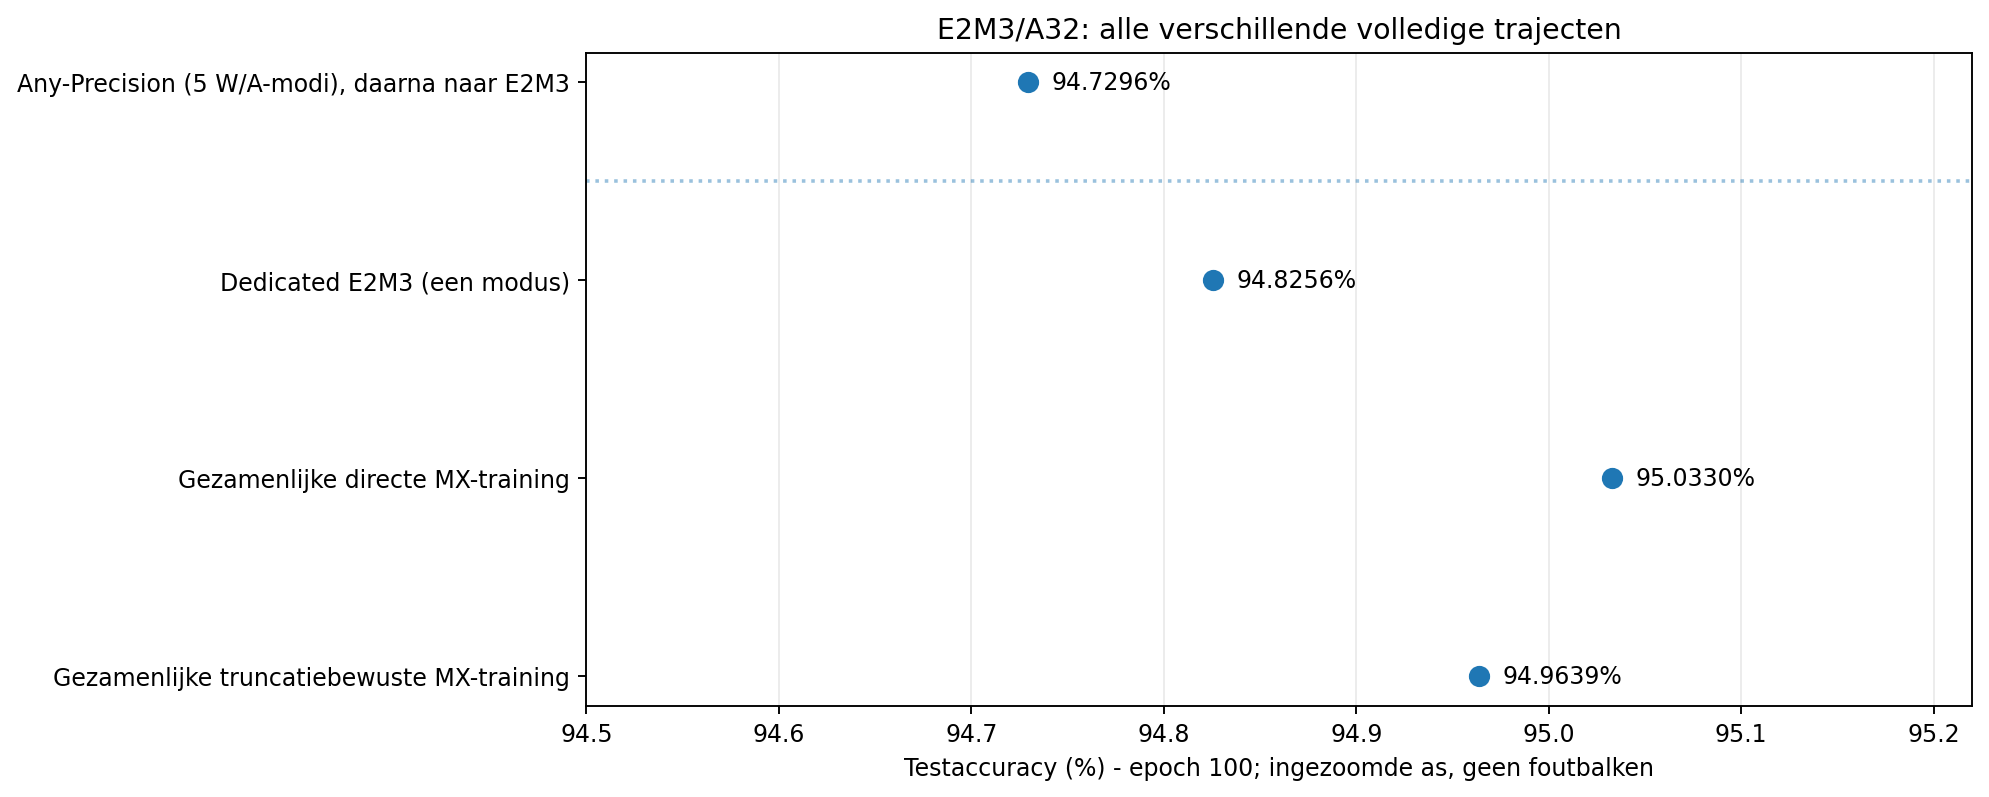

Bronnen: [cast/metrics.csv](bronnen/cast/metrics.csv).

Bronnen: [single_mx100/selected_metrics.csv](bronnen/single_mx100/selected_metrics.csv) | [dual100/selected_metrics.csv](bronnen/dual100/selected_metrics.csv) | [trunc100/selected_metrics.csv](bronnen/trunc100/selected_metrics.csv).

**Selectie is niet uniform tussen trajecten:** de conversierij gebruikt het op W32/A32 gekozen broncheckpoint; de E2M3-getrainde modellen selecteren op hun eigen E2M3-score. Daarom is de figuur epoch 100 versus epoch 100; de beste scores staan alleen aanvullend in de tabel. Een seed per traject, geen foutbalken of algemene rangorde.

In [5]:
tabel(E2M3_COMPARE[['traject','epoch','accuracy_percent','correct1','test_ce','best_epoch','best_accuracy_percent']].rename(columns={'traject':'Training / E2M3-uitvoering','epoch':'Vast eindpunt','accuracy_percent':'Epoch 100 (%)','correct1':'Correct / 26.032','test_ce':'Test-CE','best_epoch':'Geselecteerde epoch','best_accuracy_percent':'Score geselecteerd (%)'}),{'Epoch 100 (%)':'{:.4f}','Score geselecteerd (%)':'{:.4f}','Test-CE':'{:.4f}'})
fig,ax=plt.subplots(figsize=(11.8,4.8))
y=np.arange(len(E2M3_COMPARE))
ax.plot(E2M3_COMPARE.accuracy_percent,y,marker='o',linestyle='none',markersize=8)
ax.set_yticks(y,['Any-Precision (5 W/A-modi), daarna naar E2M3', 'Dedicated E2M3 (een modus)', 'Gezamenlijke directe MX-training', 'Gezamenlijke truncatiebewuste MX-training'])
ax.axhline(0.5,linestyle=':',alpha=0.45)
ax.invert_yaxis();ax.set_xlim(94.5,95.22)
for yi,value in zip(y,E2M3_COMPARE.accuracy_percent):ax.annotate(f'{value:.4f}%',(value,yi),xytext=(10,0),textcoords='offset points',va='center')
ax.set(xlabel='Testaccuracy (%) - epoch 100; ingezoomde as, geen foutbalken',title='E2M3/A32: alle verschillende volledige trajecten')
ax.grid(axis='x',alpha=0.25)
savefig(fig,'08_E2M3_alle_trajecten_epoch100')
bron(['cast'],'metrics.csv');bron(['single_mx100','dual100','trunc100'],'selected_metrics.csv')
note('**Selectie is niet uniform tussen trajecten:** de conversierij gebruikt het op W32/A32 gekozen broncheckpoint; de E2M3-getrainde modellen selecteren op hun eigen E2M3-score. Daarom is de figuur epoch 100 versus epoch 100; de beste scores staan alleen aanvullend in de tabel. Een seed per traject, geen foutbalken of algemene rangorde.')


## 2c. De nieuwe dedicated E2M1-referentie
Een vaste vierbitsmodus wordt nu ook afzonderlijk getraind. We vergelijken hetzelfde aantal optimizerupdates en hetzelfde eindpunt, maar niet hetzelfde aantal forwardpasses of dezelfde loss. De direct gezamenlijke E2M1-modus leert van een teacher; dedicated E2M1 uitsluitend van de labels.


In [6]:
z=M.final_row(D,'dedicated_e2m1_100',4)
comp=E2M1_COMPARE[E2M1_COMPARE.path!='B_round_from_E2M3']
tabel(comp[['uitvoering','accuracy_percent','delta_vs_dedicated_pp']].rename(columns={'uitvoering':'Vierbitsuitvoering','accuracy_percent':'Accuracy op epoch 100 (%)','delta_vs_dedicated_pp':'Verschil met dedicated (pp)'}),{'Accuracy op epoch 100 (%)':'{:.4f}','Verschil met dedicated (pp)':'{:+.4f}'})
r=D['reports']['dedicated_e2m1_100']
note(f"Dedicated E2M1: **{z.accuracy_percent:.4f}%** op epoch 100; beste checkpoint **epoch {r['selected_best_epoch']}**. De volledige sessie duurde **{tijd(r['session_wall_seconds'])}**. Beide checkpointrollen staan in bijlage D. Broncontrole: 200 metricrijen en 38 codehashes; checkpoints niet opnieuw uitgevoerd.")
bron(['dedicated_e2m1_100'],'run_report.json')


Vierbitsuitvoering,Accuracy op epoch 100 (%),Verschil met dedicated (pp)
Gezamenlijk direct / direct E2M1 (A),95.0254,+0.2036
Zelfde model / achteraf trunceren (C),93.5810,-1.2408
Gezamenlijk truncatiebewust / trunceren,94.9408,+0.1191
Dedicated / direct E2M1,94.8218,+0.0000


Dedicated E2M1: **94.8218%** op epoch 100; beste checkpoint **epoch 97**. De volledige sessie duurde **0:44:13**. Beide checkpointrollen staan in bijlage D. Broncontrole: 200 metricrijen en 38 codehashes; checkpoints niet opnieuw uitgevoerd.

Bronnen: [dedicated_e2m1_100/run_report.json](bronnen/dedicated_e2m1_100/run_report.json).

<a id="kloof"></a>
# 3. De kwantisatie-truncatiekloof en het herstel

**A:** rechtstreeks E2M1 afronden. **B:** vanuit de E2M3-bron opnieuw naar E2M1 afronden. **C:** uit die bron de twee laagste mantissabits verwijderen. De oorspronkelijke A/B/C-evaluatie gebruikt hetzelfde checkpoint, dezelfde gedeelde schalen en dezelfde lage BN-bank, zonder herkalibratie.

De vierde rij komt uit een **nieuw truncatiebewust getraind model**. Dat onderscheid blijft gelden, ook als het aantal epochs gelijk is.

De **vijfde rij is de nieuwe dedicated E2M1-referentie**, als afzonderlijk getraind vast vierbitsmodel. Ze hoort niet bij de A/B/C-codepadvergelijking van hetzelfde checkpoint. Haar aanwezigheid toont of flexibiliteit in dit trainingspaar een extra accuracynadeel heeft; dat nadeel wordt niet vooraf verondersteld.


Training / lage uitvoering,Accuracy (%),Correct / 26.032,Test-CE,Verschil met dedicated (pp)
Gezamenlijk direct / direct E2M1 (A),95.0254,24737,0.1976,+0.2036
Zelfde model / afronden uit E2M3 (B),94.4530,24588,0.2133,-0.3688
Zelfde model / achteraf trunceren (C),93.5810,24361,0.2294,-1.2408
Gezamenlijk truncatiebewust / trunceren,94.9408,24715,0.1944,+0.1191
Dedicated / direct E2M1,94.8218,24684,0.2492,+0.0000


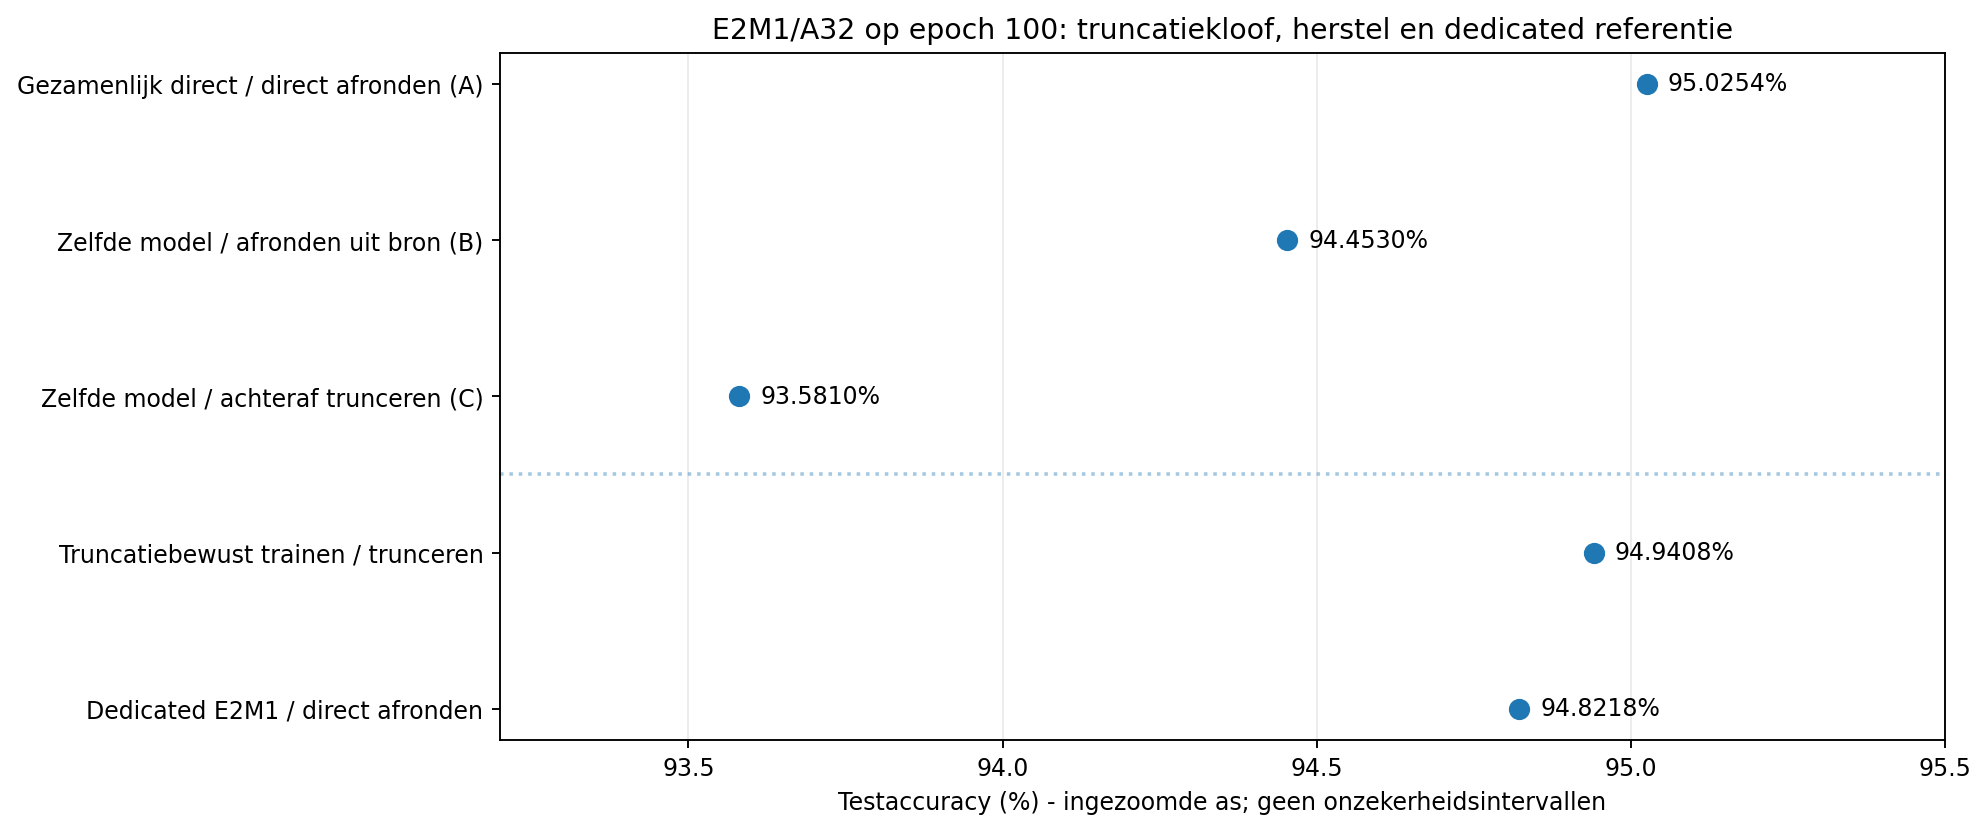

Bronnen: [gap/metrics.csv](bronnen/gap/metrics.csv).

Bronnen: [trunc100/epoch_metrics.csv](bronnen/trunc100/epoch_metrics.csv) | [dedicated_e2m1_100/epoch_metrics.csv](bronnen/dedicated_e2m1_100/epoch_metrics.csv).

In [7]:
tabel(E2M1_COMPARE[['uitvoering','accuracy_percent','correct1','test_ce','delta_vs_dedicated_pp']].rename(columns={'uitvoering':'Training / lage uitvoering','accuracy_percent':'Accuracy (%)','correct1':'Correct / 26.032','test_ce':'Test-CE','delta_vs_dedicated_pp':'Verschil met dedicated (pp)'}), {'Accuracy (%)':'{:.4f}','Test-CE':'{:.4f}','Verschil met dedicated (pp)':'{:+.4f}'})
fig, ax = plt.subplots(figsize=(11.8,5.0))
y=np.arange(len(E2M1_COMPARE))
ax.plot(E2M1_COMPARE.accuracy_percent,y,'o',markersize=8,linestyle='none')
ax.set_yticks(y,['Gezamenlijk direct / direct afronden (A)', 'Zelfde model / afronden uit bron (B)', 'Zelfde model / achteraf trunceren (C)', 'Truncatiebewust trainen / trunceren', 'Dedicated E2M1 / direct afronden'])
ax.axhline(2.5,linestyle=':',alpha=0.4)
ax.invert_yaxis();ax.set_xlim(93.2,95.5)
ax.set_xlabel('Testaccuracy (%) - ingezoomde as; geen onzekerheidsintervallen')
ax.set_title('E2M1/A32 op epoch 100: truncatiekloof, herstel en dedicated referentie')
ax.grid(axis='x',alpha=0.25)
for yi,value in zip(y,E2M1_COMPARE.accuracy_percent):ax.annotate(f'{value:.4f}%',(value,yi),xytext=(9,0),textcoords='offset points',va='center')
savefig(fig,'01_truncatiekloof_en_herstel')
bron(['gap'],'metrics.csv');bron(['trunc100','dedicated_e2m1_100'])


De vergelijking A-B toont dat tussenkwantisatie invloed kan hebben; B-C toont een bijkomend verschil tussen afronden en trunceren vanuit dezelfde bron. De accuracyverschillen zijn geen unieke causale decompositie. De **354 netto extra correcte antwoorden** na nieuwe training zijn geen per-beeld gepaarde telling: de nieuwe trainingbundel bevat daarvoor geen individuele voorspellingen. De eerdere A/B/C-evaluatie heeft wel zulke opgeslagen paren (bijlage C).

<a id="leren"></a>
# 4. Leerverloop: hoge en lage modus afzonderlijk

Accuracy en test-cross-entropy worden van echte labels berekend. De lage **trainingsloss** is daarentegen soft-target cross-entropy met de hoge modus als teacher; die mag niet rechtstreeks als dezelfde maat naast de hoge trainingsloss worden gelegd.

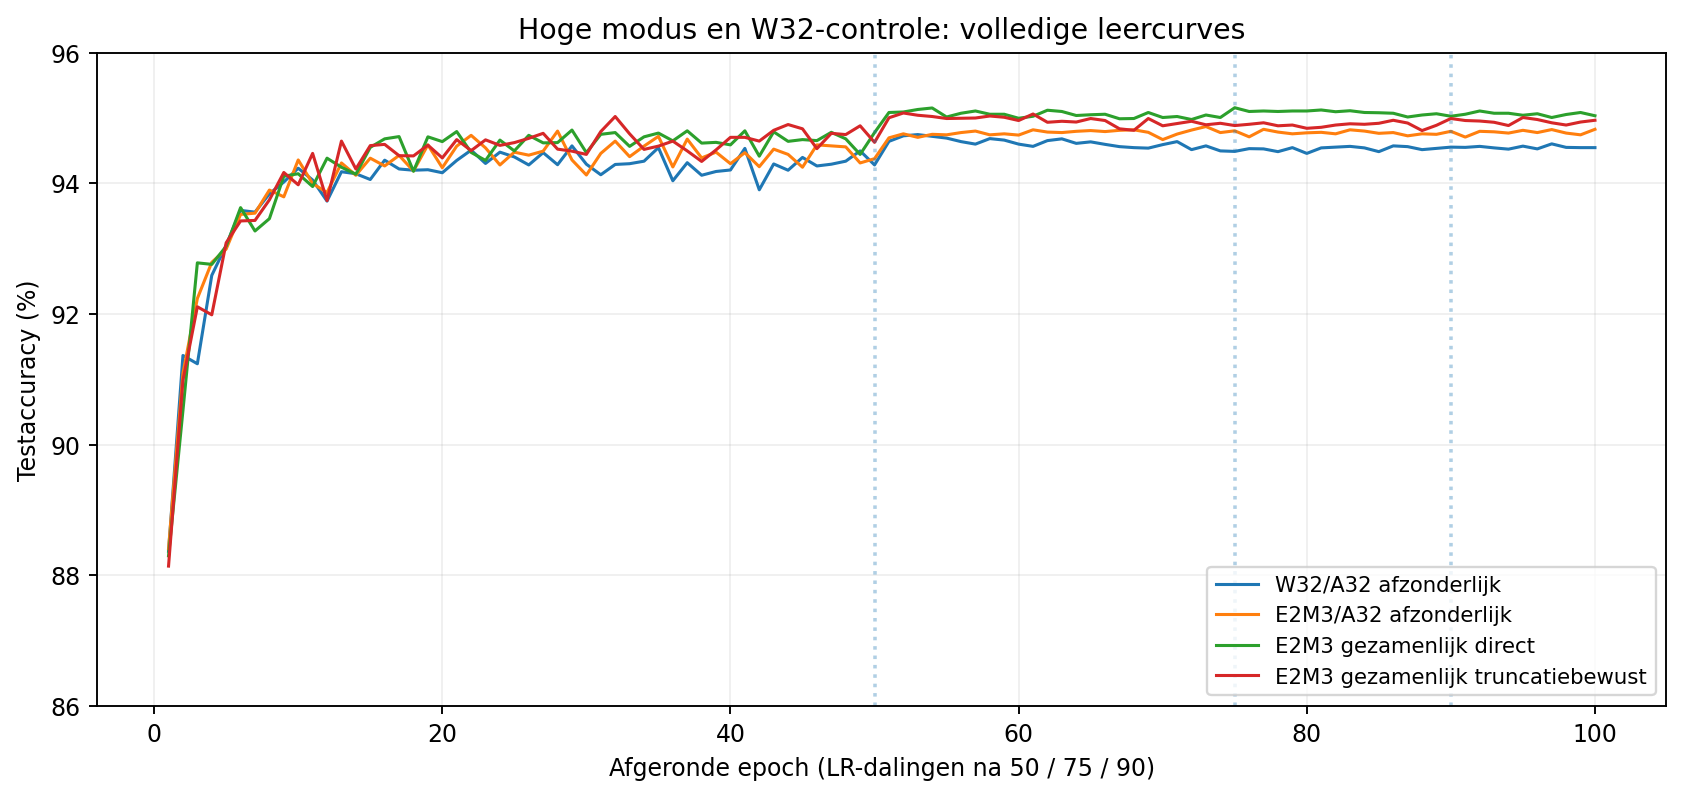

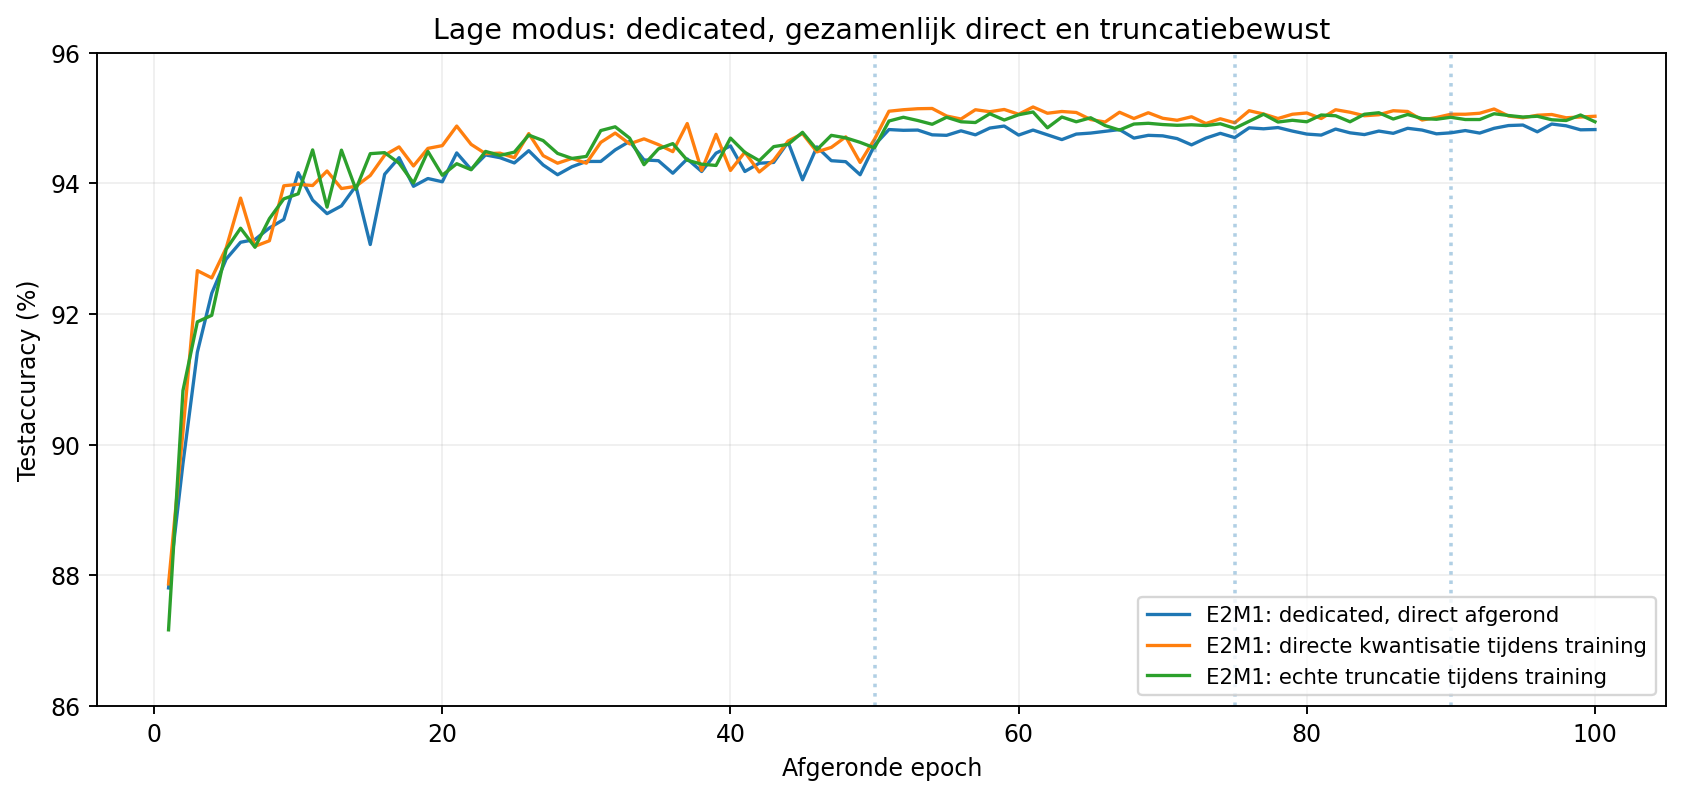

Bronnen: [single_fp100/epoch_metrics.csv](bronnen/single_fp100/epoch_metrics.csv) | [single_mx100/epoch_metrics.csv](bronnen/single_mx100/epoch_metrics.csv) | [dedicated_e2m1_100/epoch_metrics.csv](bronnen/dedicated_e2m1_100/epoch_metrics.csv) | [dual100/epoch_metrics.csv](bronnen/dual100/epoch_metrics.csv) | [trunc100/epoch_metrics.csv](bronnen/trunc100/epoch_metrics.csv).

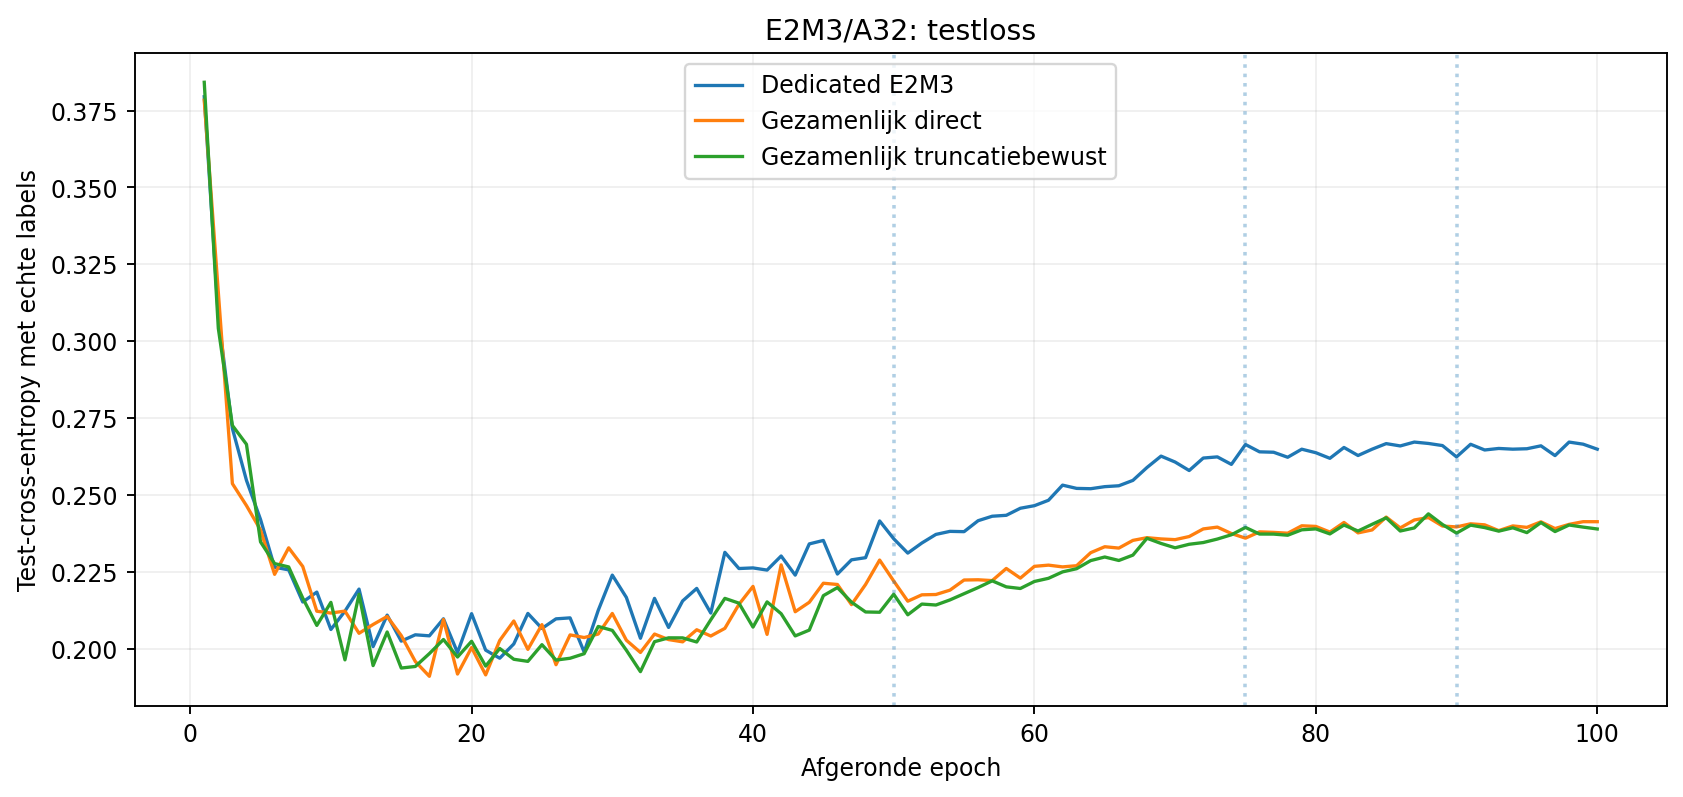

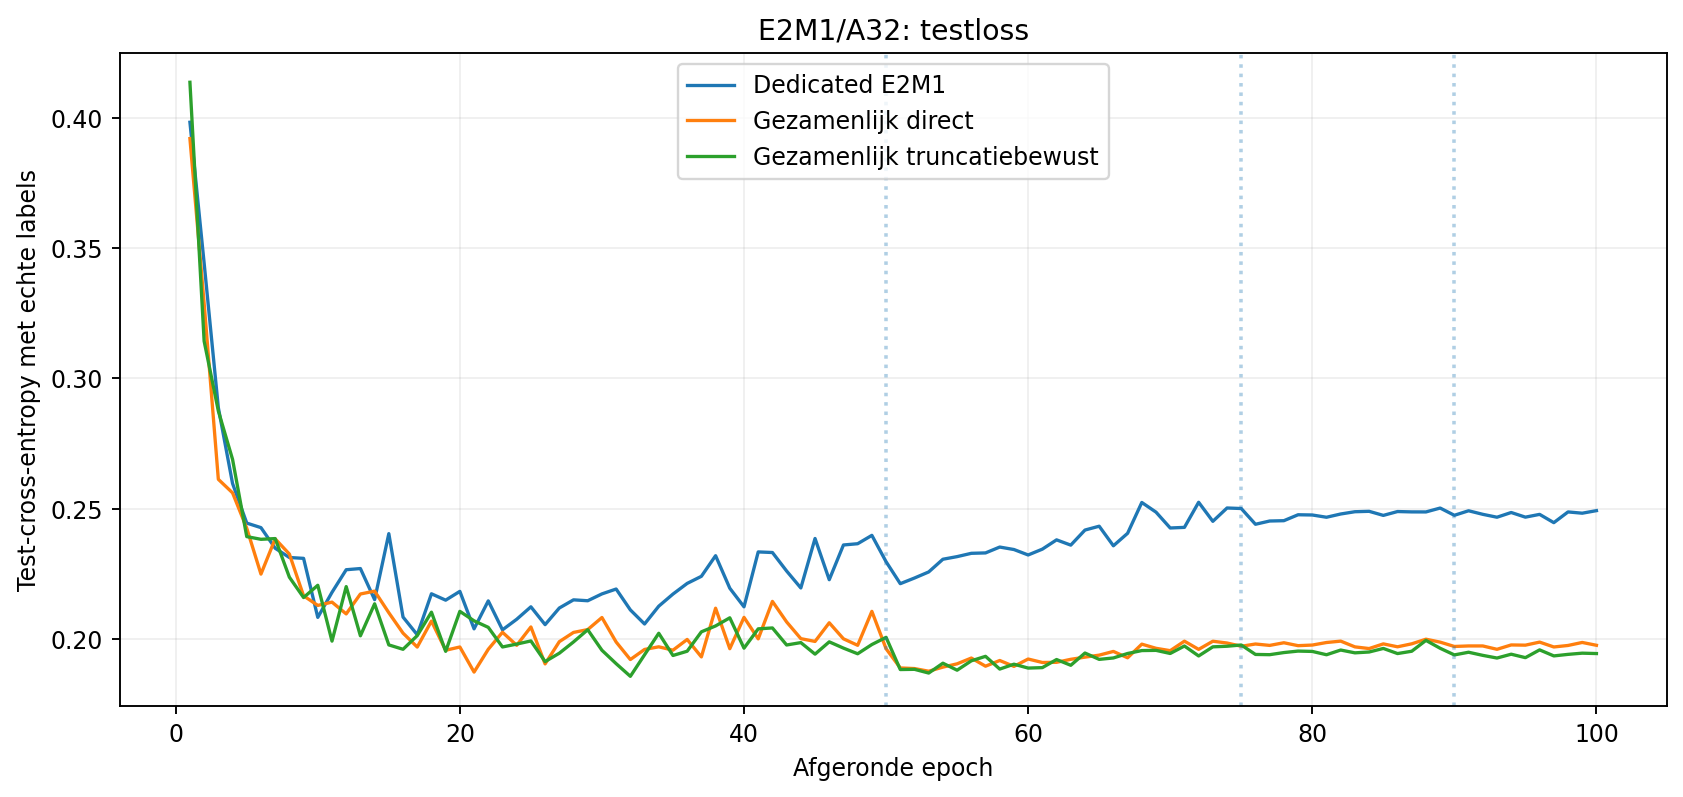

In [8]:
fig, ax = plt.subplots(figsize=(10,4.8))
for rid,label in [('single_fp100','W32/A32 afzonderlijk'),('single_mx100','E2M3/A32 afzonderlijk'),('dual100','E2M3 gezamenlijk direct'),('trunc100','E2M3 gezamenlijk truncatiebewust')]:
    bit = 32 if rid=='single_fp100' else 6
    df = D['metrics'][rid].query('phase == "test" and weight_bits == @bit')
    ax.plot(df.epoch,df.accuracy_percent,label=label,linewidth=1.3)
for e in [50,75,90]: ax.axvline(e,linestyle=':',alpha=0.35)
ax.set(xlabel='Afgeronde epoch (LR-dalingen na 50 / 75 / 90)',ylabel='Testaccuracy (%)',title='Hoge modus en W32-controle: volledige leercurves',ylim=(86,96))
ax.legend(loc='lower right',fontsize=9);ax.grid(alpha=0.2)
savefig(fig,'02_leercurve_hoge_modus')

fig, ax = plt.subplots(figsize=(10,4.8))
for rid,label in [('dedicated_e2m1_100','E2M1: dedicated, direct afgerond'),('dual100','E2M1: directe kwantisatie tijdens training'),('trunc100','E2M1: echte truncatie tijdens training')]:
    df = D['metrics'][rid].query('phase == "test" and weight_bits == 4')
    ax.plot(df.epoch,df.accuracy_percent,label=label,linewidth=1.4)
for e in [50,75,90]: ax.axvline(e,linestyle=':',alpha=0.35)
ax.set(xlabel='Afgeronde epoch',ylabel='Testaccuracy (%)',title='Lage modus: dedicated, gezamenlijk direct en truncatiebewust',ylim=(86,96))
ax.legend(loc='lower right',fontsize=9);ax.grid(alpha=0.2)
savefig(fig,'03_leercurve_lage_modus')
bron(M.FULL)
for bit,configs,filename in [
    (6,[('single_mx100','Dedicated E2M3'),('dual100','Gezamenlijk direct'),('trunc100','Gezamenlijk truncatiebewust')],'10_testloss_E2M3'),
    (4,[('dedicated_e2m1_100','Dedicated E2M1'),('dual100','Gezamenlijk direct'),('trunc100','Gezamenlijk truncatiebewust')],'11_testloss_E2M1')]:
    fig,ax=plt.subplots(figsize=(10,4.8))
    for rid,label in configs:
        q=D['metrics'][rid].query('phase == "test" and weight_bits == @bit')
        ax.plot(q.epoch,q.objective_loss,label=label,linewidth=1.4)
    for e in [50,75,90]:ax.axvline(e,linestyle=':',alpha=0.35)
    ax.set(xlabel='Afgeronde epoch',ylabel='Test-cross-entropy met echte labels',title=f'{"E2M3" if bit==6 else "E2M1"}/A32: testloss')
    ax.legend();ax.grid(alpha=0.2);savefig(fig,filename)


<a id="opslag"></a>
# 5. Minder bits: welk voordeel is al onderbouwd?

**MXFP is zelf ook floating-point.** De vergelijking hier is vooral met **FP32**, niet met iedere mogelijke FP- of integerrepresentatie. De winst van smallere elementen is niet uniek voor truncatie. Truncatie voegt de mogelijkheid toe om meerdere precisies uit **dezelfde compacte bron** af te leiden.

Volgens de gebruikte MX-formaten delen 32 elementen een E8M0-schaal van 8 bits [L1, p.3, tabel 1]. Per volledig blok geldt:

`gemiddelde bits per element = lokale elementbits + 8 / 32`

Dit is 6,25 voor E2M3 en 4,25 voor E2M1, **niet exact 6 en 4 inclusief alle overhead**. De concrete CNN heeft daarnaast onvolledige blokken en niet-gekwantiseerde lagen.

In [9]:
bit_table = pd.DataFrame([
    {'Representatie':'FP32','Lokale bits':32,'Schaalbits per element':0.0,'Totaal per volledig blokelement':32.0,'Status':'Referentiegewichten in FP32'},
    {'Representatie':'FP16','Lokale bits':16,'Schaalbits per element':0.0,'Totaal per volledig blokelement':16.0,'Status':'Alleen breedtecontext; geen gemeten FP16-accuracy'},
    {'Representatie':'MXFP6 E2M3','Lokale bits':6,'Schaalbits per element':8/32,'Totaal per volledig blokelement':6+8/32,'Status':'Onderzocht'},
    {'Representatie':'MXFP4 E2M1','Lokale bits':4,'Schaalbits per element':8/32,'Totaal per volledig blokelement':4+8/32,'Status':'Onderzocht'},
])
tabel(bit_table,{'Schaalbits per element':'{:.2f}','Totaal per volledig blokelement':'{:.2f}'})
note(f"""**Concrete layout van de zes CNN-lagen (herberekend):** {S['n_weights']:,} echte gewichten, {S['blocks']:,} blokken en {S['padding']:,} opvulplaatsen. De gedeelde schalen nemen {S['scale_bytes']:,} bytes in. Eerste/laatste laag, biases en **alle vijf bewaarde BN-banken met buffers** nemen samen nog {S['auxiliary_bytes']:,} bytes in.

Een ongegroepeerde uniforme vierbitscode is nominaal kleiner dan 4,25 bits. De huidige resultaten bewijzen dus niet dat MX bij dezelfde bitbreedte altijd minder opslag of hogere accuracy heeft dan uniforme integerkwantisatie.""")
storage_display=REPRESENTATIES[['representatie','weight_code_bytes','shared_scale_bytes','auxiliary_bytes','total_bytes']].copy()
storage_display['Totaal (KiB)']=storage_display.total_bytes/1024
storage_display=storage_display.rename(columns={'representatie':'Inhoud','weight_code_bytes':'Gewichtscodes (B)','shared_scale_bytes':'Schalen (B)','auxiliary_bytes':'Overige staat (B)','total_bytes':'Totaal (B)'})
tabel(storage_display,{'Totaal (KiB)':'{:.2f}'})
note('**Alle waarden in deze tabel zijn tensor-/code-inhoud, zonder bestandheaders, optimizer, activaties of tijdelijke GPU-buffers.** 1 KiB = 1.024 bytes. De lage kopie bewaart alleen de vierbitsuitvoering; zij kan de hoge bron niet vervangen als terugschakelen nodig blijft.')
bron(['trunc100'],'mx_export_layers_6_last.csv');bron(['trunc100'],'mx_export_layers_4_last.csv')

Representatie,Lokale bits,Schaalbits per element,Totaal per volledig blokelement,Status
FP32,32,0.00,32.00,Referentiegewichten in FP32
FP16,16,0.00,16.00,Alleen breedtecontext; geen gemeten FP16-accuracy
MXFP6 E2M3,6,0.25,6.25,Onderzocht
MXFP4 E2M1,4,0.25,4.25,Onderzocht


**Concrete layout van de zes CNN-lagen (herberekend):** 129,472 echte gewichten, 4,080 blokken en 1,088 opvulplaatsen. De gedeelde schalen nemen 4,080 bytes in. Eerste/laatste laag, biases en **alle vijf bewaarde BN-banken met buffers** nemen samen nog 19,248 bytes in.

Een ongegroepeerde uniforme vierbitscode is nominaal kleiner dan 4,25 bits. De huidige resultaten bewijzen dus niet dat MX bij dezelfde bitbreedte altijd minder opslag of hogere accuracy heeft dan uniforme integerkwantisatie.

Inhoud,Gewichtscodes (B),Schalen (B),Overige staat (B),Totaal (B),Totaal (KiB)
FP32-referentie,517888,0,19248,537136,524.55
E2M3-bron (ondersteunt 6 en 4 bit),97920,4080,19248,121248,118.41
E2M1-uitvoeringskopie (alleen 4 bit),65280,4080,19248,88608,86.53


**Alle waarden in deze tabel zijn tensor-/code-inhoud, zonder bestandheaders, optimizer, activaties of tijdelijke GPU-buffers.** 1 KiB = 1.024 bytes. De lage kopie bewaart alleen de vierbitsuitvoering; zij kan de hoge bron niet vervangen als terugschakelen nodig blijft.

Bronnen: [trunc100/mx_export_layers_6_last.csv](bronnen/trunc100/mx_export_layers_6_last.csv).

Bronnen: [trunc100/mx_export_layers_4_last.csv](bronnen/trunc100/mx_export_layers_4_last.csv).

De laagvormen en datatypegroottes zijn afzonderlijk uit de werkelijk aangeleverde CNN-code geinventariseerd, zonder training. Zie [tensorinventaris](bronnen/tensorinventaris.json) en [oorspronkelijke CNN-code](bronnen/code/models/svhn_quan.py). De 19.248 bytes aanvullende staat zijn ook in de vroegere conversiebundel gerapporteerd. Er is **geen BN-pruning ingevoerd** om een mooier opslaggetal te verkrijgen.

De nieuw gerapporteerde dedicated E2M1-export bevat eveneens **69.360 bytes gewichten plus schalen** voor de zes lagen. Met dezelfde behouden modelbijgegevens is dat **88.608 bytes** ruwe modelinhoud. Dit is een vaste vierbitskopie, geen bron om ook de oorspronkelijke zesbitsgewichten terug te krijgen. De gerapporteerde fysieke export is groter door serialisatie en metadata; zie de aparte tabel hieronder.


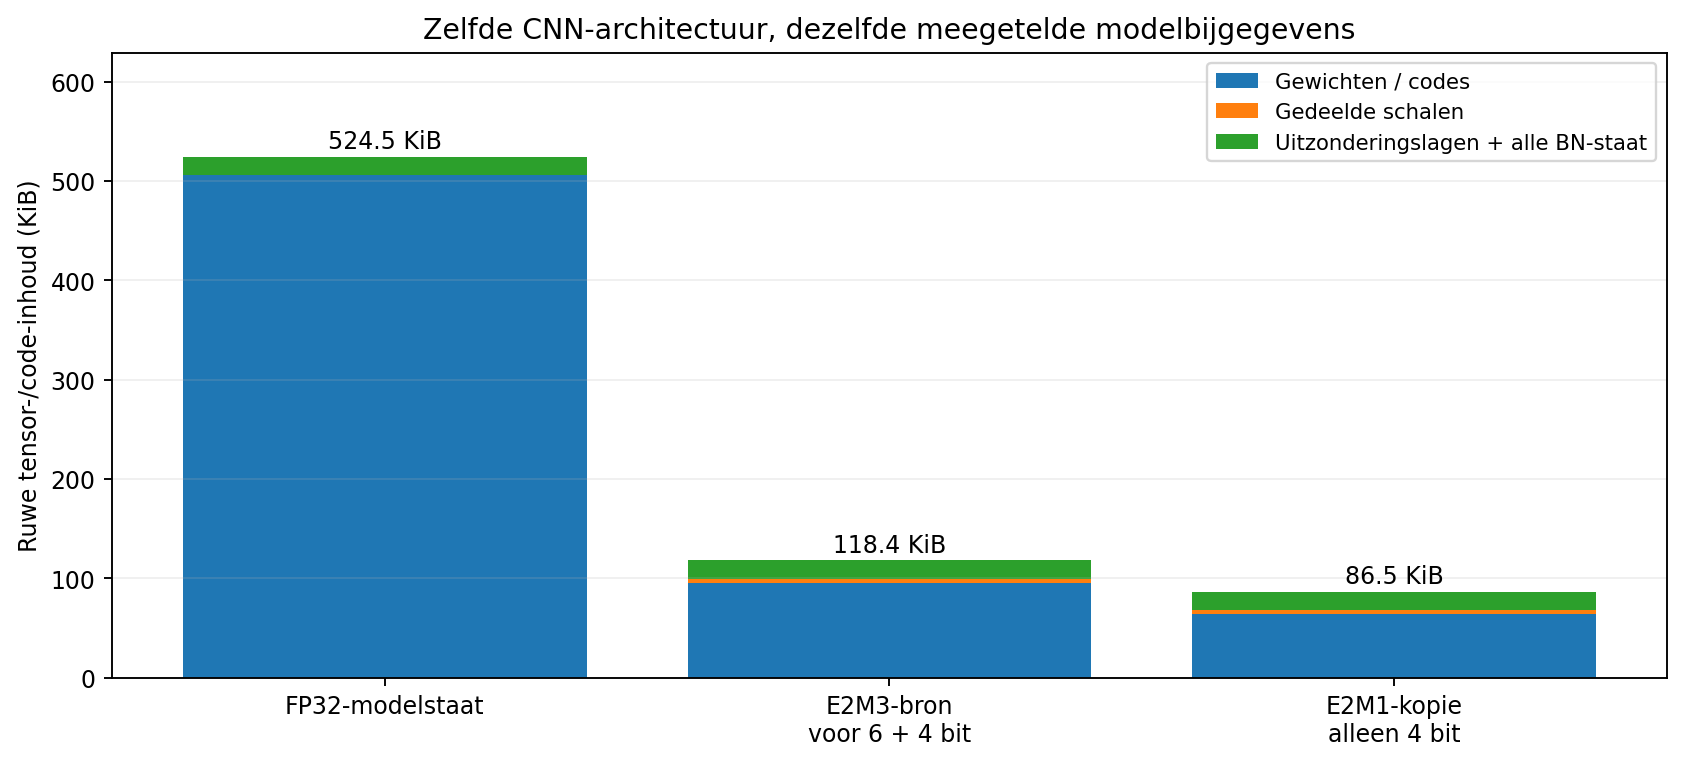

Voor de zes gewichten is E2M3 **5.08 keer kleiner** dan FP32. Inclusief dezelfde overige staat is de hoge bron **4.43 keer kleiner**. De precisiewissel zelf verkleint de **bewaarde hoge bron niet**; we blijven die houden om later terug te kunnen naar E2M3.

In [10]:
fig,ax=plt.subplots(figsize=(10,4.6))
x=np.arange(len(REPRESENTATIES));bottom=np.zeros(len(x))
for col,label in [('weight_code_bytes','Gewichten / codes'),('shared_scale_bytes','Gedeelde schalen'),('auxiliary_bytes','Uitzonderingslagen + alle BN-staat')]:
    vals=REPRESENTATIES[col].to_numpy()/1024
    ax.bar(x,vals,bottom=bottom,label=label)
    bottom+=vals
ax.set_xticks(x,['FP32-modelstaat','E2M3-bron\nvoor 6 + 4 bit','E2M1-kopie\nalleen 4 bit'])
for i,v in enumerate(bottom):ax.text(i,v+8,f'{v:.1f} KiB',ha='center')
ax.set_ylim(0,max(bottom)*1.2)
ax.set(ylabel='Ruwe tensor-/code-inhoud (KiB)',title='Zelfde CNN-architectuur, dezelfde meegetelde modelbijgegevens')
ax.legend(loc='upper right',fontsize=9);ax.grid(axis='y',alpha=0.2)
savefig(fig,'04_bits_en_modelinhoud')
note(f"""Voor de zes gewichten is E2M3 **{S['six_weights_ratio_fp32_to_high']:.2f} keer kleiner** dan FP32. Inclusief dezelfde overige staat is de hoge bron **{S['all_state_ratio_fp32_to_high']:.2f} keer kleiner**. De precisiewissel zelf verkleint de **bewaarde hoge bron niet**; we blijven die houden om later terug te kunnen naar E2M3.""")

<a id="bron"></a>
# 6. Het specifieke voordeel: een bron voor twee modi

Een eerlijk vergelijk specificeert eerst de functie: **beide getrainde uitvoeringsprecisies beschikbaar houden**. Daarvoor zijn verschillende opslagstrategieen mogelijk.

Bij onze directe tweemodusreferentie zijn de schalen en overige modelstaat van de hoge en lage export gelijk; dit is gecontroleerd in de A/B/C-evaluatie. Daarom tonen we ook een gunstige directe opslagvariant die deze gegevens deelt, niet alleen twee dubbel opgeslagen bestanden. Dat gedeelde containerformaat is een **berekend scenario**, nog geen gebouwd bestand.

| Strategie | Wat bewaren we? | Hoe schakelen we? |
|---|---|---|
| 1. FP32-bron | FP32-gewichten en overige modelstaat | Naar de gewenste MX-modus herkwantiseren. |
| 2. Twee directe codesets, bijgegevens gedeeld | E2M3-codes en E2M1-codes; gemeenschappelijke schalen/overige staat eenmaal | De gewenste codeset selecteren. |
| 3. Twee zelfstandige exports | Dezelfde codesets, maar schalen/overige staat per export | Het gewenste exportbestand selecteren. |
| 4. Een hoge bron met truncatie | E2M3-codes, schalen en overige staat | Hoge modus rechtstreeks; lage modus via codes >> 2. |

**Dit zijn vier opslagstrategieen, geen vier trainingen.** Strategie 3 bestaat uit twee exports van hetzelfde gezamenlijke model, niet twee dedicated trainingen. Strategie 2 behoudt beide benodigde BN-banken; alleen de duplicaten tussen bestanden verdwijnen. Strategie 4 bewaart de hoge bron ook wanneer de lage modus actief is. Alleen E2M1 nodig? Dan is een vaste vierbitskopie kleiner, maar die ondersteunt geen terugkeer naar de oorspronkelijke hoge codes.


Strategie voor twee beschikbare modi,Gewichten/codes (B),Schalen (B),Overige staat (B),Totaal (B),Totaal (KiB)
"FP32-bron, doelprecisie herkwantiseren",517888,0,19248,537136,524.55
"Twee directe MX-codesets, metadata gedeeld",163200,4080,19248,186528,182.16
Twee zelfstandige exports van hetzelfde gezamenlijke model,163200,8160,38496,209856,204.94
Een E2M3-bron met mantissatruncatie,97920,4080,19248,121248,118.41


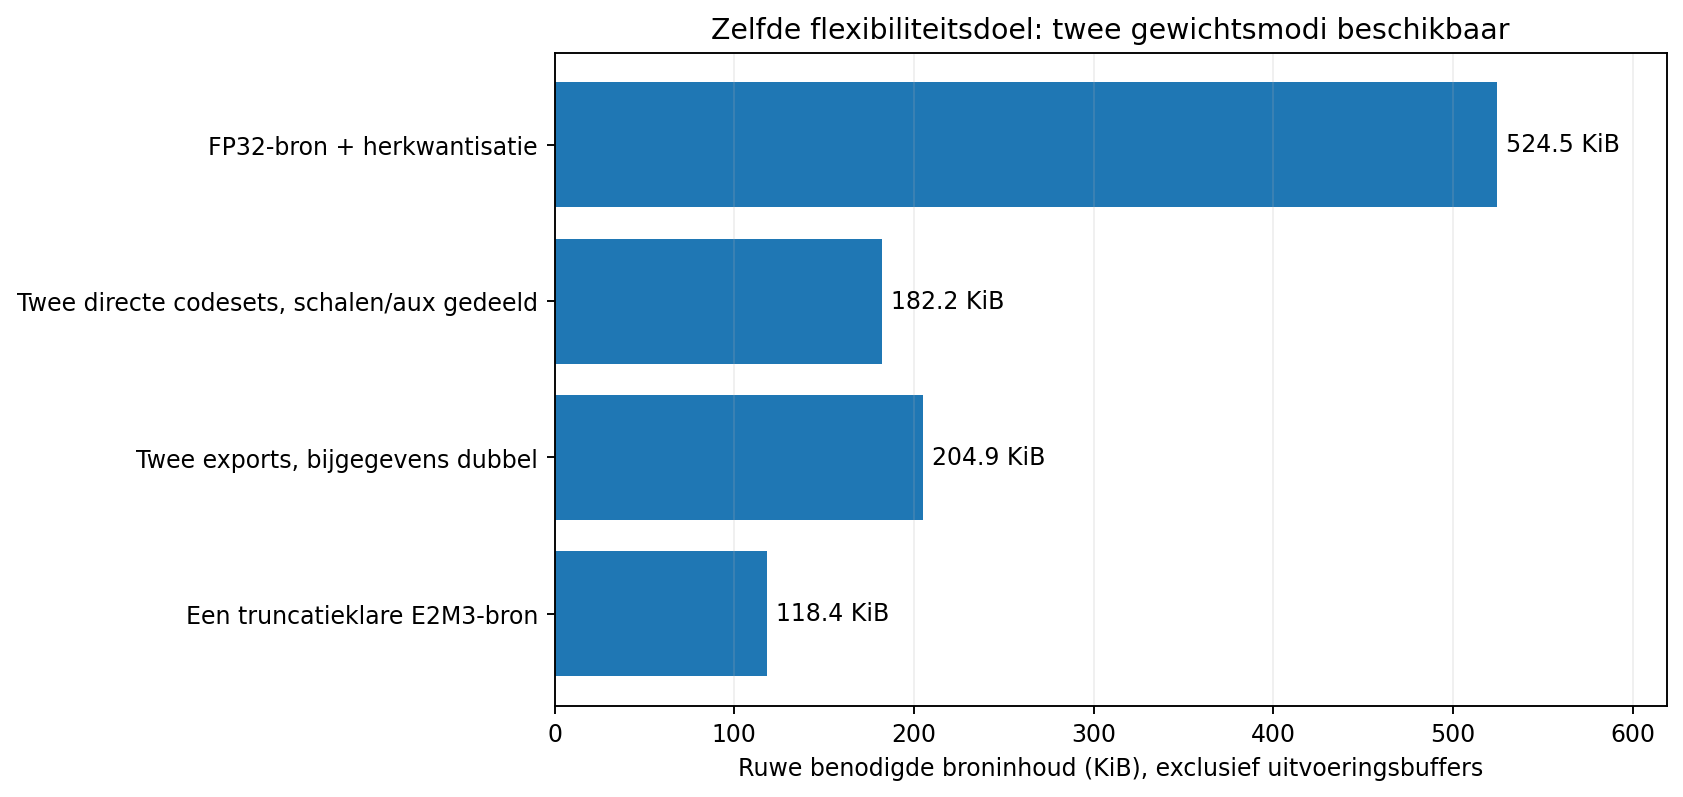

**Relevante MX-versus-MX-winst:** tegenover twee directe codesets met gedeelde schalen en overige staat bespaart de ene hoge bron **35.00%** aan deze berekende broninhoud. De 6- en 4-bit directe codesets hebben samen 186,528 bytes nodig; de truncatiebron 121,248 bytes.

Dit is **niet** nog eens de 4,43x-winst tegenover FP32. Het zijn twee verschillende referenties. De nieuwe dedicated E2M1-accuracy is gemeten en staat in sectie 3. Strategie 3 blijft echter twee exports van hetzelfde gezamenlijke model. Twee onafhankelijk getrainde dedicated modellen hebben hun eigen waarden en normalisaties; hun grootte mag niet door het delen van ongelijk geworden data worden verkleind.

Onze meetopslag bewaart best, last, FP32-hervatcheckpoints en lage controle-exports. Voor de minimale **inferentiebron per geselecteerd checkpoint** is alleen de hoge export nodig; onderzoeksarchiefgrootte is een andere maat.

In [11]:
ss=SCENARIOS[['scenario','code_bytes','scale_bytes','aux_bytes','total_bytes']].copy()
ss['Totaal (KiB)']=ss.total_bytes/1024
ss=ss.rename(columns={'scenario':'Strategie voor twee beschikbare modi','code_bytes':'Gewichten/codes (B)','scale_bytes':'Schalen (B)','aux_bytes':'Overige staat (B)','total_bytes':'Totaal (B)'})
tabel(ss,{'Totaal (KiB)':'{:.2f}'})
fig,ax=plt.subplots(figsize=(10,4.8))
x=np.arange(len(SCENARIOS));vals=SCENARIOS.total_bytes.to_numpy()/1024
ax.barh(x,vals);ax.set_yticks(x,['FP32-bron + herkwantisatie','Twee directe codesets, schalen/aux gedeeld','Twee exports, bijgegevens dubbel','Een truncatieklare E2M3-bron'])
ax.invert_yaxis();ax.set_xlim(0,vals.max()*1.18)
for i,v in enumerate(vals):ax.text(v+5,i,f'{v:.1f} KiB',va='center')
ax.set(xlabel='Ruwe benodigde broninhoud (KiB), exclusief uitvoeringsbuffers',title='Zelfde flexibiliteitsdoel: twee gewichtsmodi beschikbaar')
ax.grid(axis='x',alpha=0.2)
savefig(fig,'05_een_bron_meerdere_precisies')
note(f"""**Relevante MX-versus-MX-winst:** tegenover twee directe codesets met gedeelde schalen en overige staat bespaart de ene hoge bron **{S['source_dedup_reduction_pct']:.2f}%** aan deze berekende broninhoud. De 6- en 4-bit directe codesets hebben samen {S['source_two_dedup_bytes']:,} bytes nodig; de truncatiebron {S['source_high_all_bytes']:,} bytes.

Dit is **niet** nog eens de 4,43x-winst tegenover FP32. Het zijn twee verschillende referenties. De nieuwe dedicated E2M1-accuracy is gemeten en staat in sectie 3. Strategie 3 blijft echter twee exports van hetzelfde gezamenlijke model. Twee onafhankelijk getrainde dedicated modellen hebben hun eigen waarden en normalisaties; hun grootte mag niet door het delen van ongelijk geworden data worden verkleind.

Onze meetopslag bewaart best, last, FP32-hervatcheckpoints en lage controle-exports. Voor de minimale **inferentiebron per geselecteerd checkpoint** is alleen de hoge export nodig; onderzoeksarchiefgrootte is een andere maat.""")

### Bestandsgrootte, trainingsgeheugen en dataverkeer zijn andere dingen

De huidige `.pt`-exports bevatten ook metadata en serialisatie. De exacte bestandgroottes hieronder zijn **door jouw runner gerapporteerd**, niet opnieuw opgemeten aan hier beschikbare exportbytes. Het vergelijken van een exportbestand met een veel groter Adam-hervatcheckpoint zou oneerlijk zijn.

In [12]:
tabel(FYSIEK[['run_id','bits','reported_file_bytes','raw_tensor_bytes','full_test_rerun']].rename(columns={'run_id':'Run','bits':'Bits','reported_file_bytes':'Gerapporteerd bestand (B)','raw_tensor_bytes':'Ruwe tensorinhoud (B)','full_test_rerun':'Nieuwe volledige export-testpass'}))
note(f"""**Geen volledige trainingsgeheugenbesparing aangetoond.** De FP32-masters en Adam-momenten blijven tijdens training bestaan. De emulatie gebruikt bovendien FP32-convolutiebuffers, A32-activaties en tijdelijke broncaches. De opslagfactor uit sectie 5 mag daarom niet als VRAM-, energie- of snelheidswinst worden gepresenteerd.

**Dataverkeer (alleen potentieel):** een volledig gepakt MX-blok bevat 25 bytes in E2M3 en 17 bytes in E2M1. Een overdracht van de zes lage gewichtstensors zou {S['low_bytes']:,} in plaats van {S['high_bytes']:,} bytes bevatten: **32% minder** voor dat gewichtspayload. Dit geldt alleen wanneer de geheugenlayout/streamer werkelijk de lagere breedte transporteert. Een volledige zesbitsbron lezen en pas daarna shiften bespaart niet automatisch 32% aan bronlezingen. Activaties, hergebruik, busuitlijning en metadata vallen buiten deze telling. Er is nog geen gemeten bandbreedte-, energie- of latencywinst.""")

Run,Bits,Gerapporteerd bestand (B),Ruwe tensorinhoud (B),Nieuwe volledige export-testpass
single_mx100,6,163941,121248,False
dedicated_e2m1_100,4,131301,88608,False
dual100,6,163813,121248,False
dual100,4,131173,88608,False
trunc100,6,164005,121248,False
trunc100,4,131621,88608,False


**Geen volledige trainingsgeheugenbesparing aangetoond.** De FP32-masters en Adam-momenten blijven tijdens training bestaan. De emulatie gebruikt bovendien FP32-convolutiebuffers, A32-activaties en tijdelijke broncaches. De opslagfactor uit sectie 5 mag daarom niet als VRAM-, energie- of snelheidswinst worden gepresenteerd.

**Dataverkeer (alleen potentieel):** een volledig gepakt MX-blok bevat 25 bytes in E2M3 en 17 bytes in E2M1. Een overdracht van de zes lage gewichtstensors zou 69,360 in plaats van 102,000 bytes bevatten: **32% minder** voor dat gewichtspayload. Dit geldt alleen wanneer de geheugenlayout/streamer werkelijk de lagere breedte transporteert. Een volledige zesbitsbron lezen en pas daarna shiften bespaart niet automatisch 32% aan bronlezingen. Activaties, hergebruik, busuitlijning en metadata vallen buiten deze telling. Er is nog geen gemeten bandbreedte-, energie- of latencywinst.

<a id="afweging"></a>
# 7. Accuracy tegenover compacte gewichtsinhoud

Hier combineren we **gemeten testaccuracies** met **de berekende omvang van een actieve gepakte modelkopie**. Alle punten hebben A32 en dezelfde zes MX-doellagen. De x-as is **niet** de blijvende bron die beide modi ondersteunt, en ook niet gemeten VRAM. Voor die bron is sectie 6 leidend.

De directe en truncatiebewuste E2M1-kopie hebben dezelfde grootte; de methode verandert vooral of de lage kopie zonder aparte codeset uit de hoge bron kan ontstaan en welke accuracy daarbij behouden blijft.

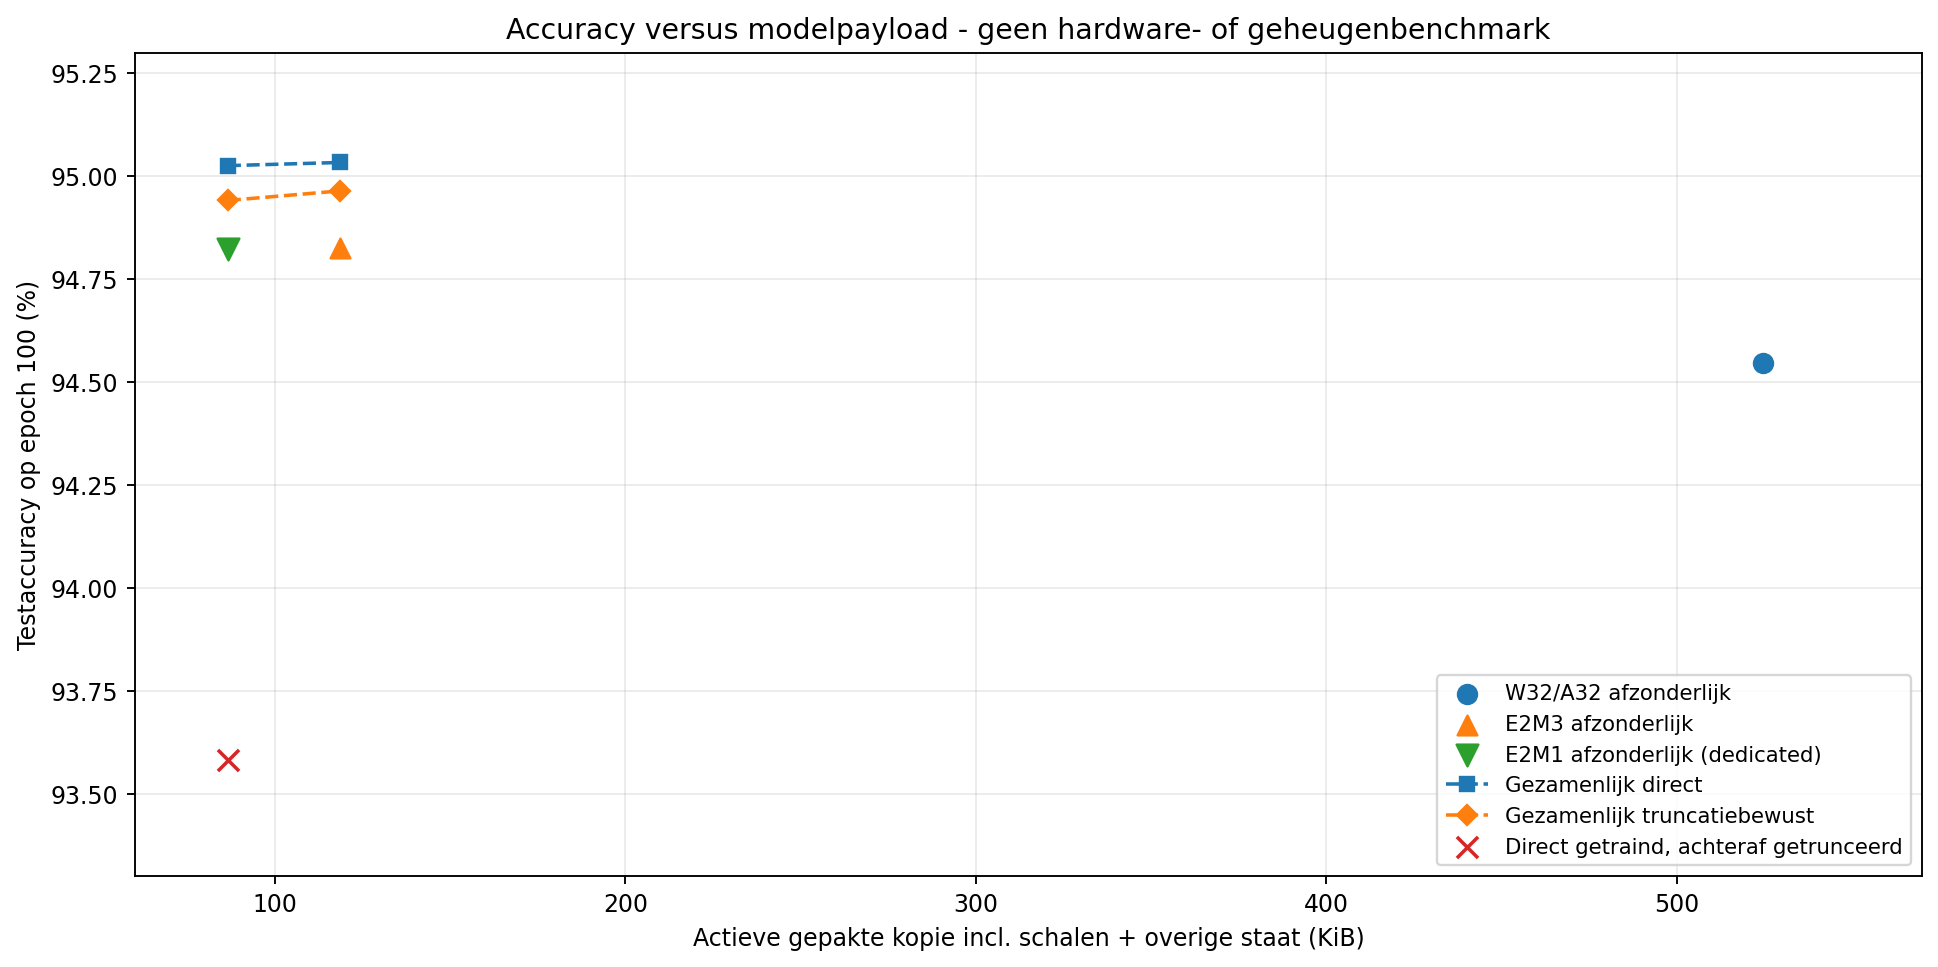

Training,Trainpasses per batch,Epochs totaal,Volledige sessie
Any-Precision vijf W/A-modi,5,1:01:57,1:02:04
W32/A32 afzonderlijk,1,0:25:51,0:25:59
E2M3/A32 afzonderlijk,1,0:47:38,0:47:46
E2M1/A32 afzonderlijk,1,0:44:05,0:44:13
Gezamenlijk: directe MX-kwantisatie,2,1:16:41,1:16:49
Gezamenlijk: truncatiebewust,2,1:05:39,1:05:47


Bronnen: [any100/epoch_times.csv](bronnen/any100/epoch_times.csv) | [single_fp100/epoch_times.csv](bronnen/single_fp100/epoch_times.csv) | [single_mx100/epoch_times.csv](bronnen/single_mx100/epoch_times.csv) | [dedicated_e2m1_100/epoch_times.csv](bronnen/dedicated_e2m1_100/epoch_times.csv) | [dual100/epoch_times.csv](bronnen/dual100/epoch_times.csv) | [trunc100/epoch_times.csv](bronnen/trunc100/epoch_times.csv).

**Werkelijk gemeten emulatietijd**, inclusief onze logging/controles; geen iso-compute vergelijking. Verschillen in passes, codec, bronhergebruik en laptopbelasting kunnen meespelen. Reken deze runtimes niet om naar een hardware-energiewinst.

In [13]:
fig,ax=plt.subplots(figsize=(11.5,5.8))
ax.scatter([S['fp32_all_state_bytes']/1024],[M.final_row(D,'single_fp100',32).accuracy_percent],marker='o',s=65,label='W32/A32 afzonderlijk')
ax.scatter([S['source_high_all_bytes']/1024],[M.final_row(D,'single_mx100',6).accuracy_percent],marker='^',s=70,label='E2M3 afzonderlijk')
ax.scatter([S['view_low_all_bytes']/1024],[M.final_row(D,'dedicated_e2m1_100',4).accuracy_percent],marker='v',s=85,label='E2M1 afzonderlijk (dedicated)')
for rid,label,mark in [('dual100','Gezamenlijk direct','s'),('trunc100','Gezamenlijk truncatiebewust','D')]:
    xs=[S['view_low_all_bytes']/1024,S['source_high_all_bytes']/1024]
    ys=[M.final_row(D,rid,4).accuracy_percent,M.final_row(D,rid,6).accuracy_percent]
    ax.plot(xs,ys,marker=mark,linestyle='--',label=label,markersize=6)
ax.scatter([S['view_low_all_bytes']/1024],[M.gap_row(D,'C_truncate_E2M3').accuracy_percent],marker='x',s=80,label='Direct getraind, achteraf getrunceerd')
ax.set(xlabel='Actieve gepakte kopie incl. schalen + overige staat (KiB)',ylabel='Testaccuracy op epoch 100 (%)',title='Accuracy versus modelpayload - geen hardware- of geheugenbenchmark',ylim=(93.3,95.3),xlim=(60,570))
ax.legend(loc='lower right',fontsize=9);ax.grid(alpha=0.25)
savefig(fig,'06_accuracy_tegen_modelpayload')
T=TIJD.copy();T['Epochs totaal']=T.epoch_total_s.map(tijd);T['Volledige sessie']=T.session_s.map(tijd)
tabel(T[['methode','passes_per_batch','Epochs totaal','Volledige sessie']].rename(columns={'methode':'Training','passes_per_batch':'Trainpasses per batch'}))
bron(['any100']+M.FULL,'epoch_times.csv')
note('**Werkelijk gemeten emulatietijd**, inclusief onze logging/controles; geen iso-compute vergelijking. Verschillen in passes, codec, bronhergebruik en laptopbelasting kunnen meespelen. Reken deze runtimes niet om naar een hardware-energiewinst.')

<a id="vervolg"></a>
# 8. Wat is nog nodig, en wat niet voor deze meeting?

**Voor dit resultatenoverzicht is geen nieuwe training nodig.** De meetwaarden en transparante opslagberekeningen zijn al beschikbaar. Het notebook gebruikt uitsluitend die gegevens.

**De eerder voorgestelde volgende proef is een exportcontrole, geen verbeteringsmethode:** in een nieuw proces uitsluitend `mx_source_E2M3_best.pt` of `mx_source_E2M3_last.pt` laden; daaruit zowel E2M3 als getrunceerd E2M1 reconstrueren met de juiste BN-bank; beide opnieuw op de volledige testset evalueren. Geen mastercheckpoint, geen optimizer, geen updates. De huidige exporttest bevestigt exacte gewichtstensors, maar een volledige nieuwe testpass vanuit de laatste truncatiebewuste exports is nog niet uitgevoerd. De opgeslagen aanvullende staat omvat de noodzakelijke uitzonderingslagen en BN-banken.

**Voor sterkere claims zijn aanvullende proeven nodig:**

- **Dedicated versus gezamenlijk bij vier bit:** de dedicated E2M1/A32-training is nu toegevoegd. Het resterende aandachtspunt is herhaling over seeds en afbakening van de verschillende losses/passes; niet meer een ontbrekend vierbitsdatapunt.
- **Robuustheid:** meerdere seeds met vooraf vastgelegde evaluatie; toekomstige modelkeuzes op een ontwikkelvalidatieset in plaats van steeds de testset. De huidige testselectie achteraf niet als onafhankelijk labelen.
- **Generalisatie en systeemvoordeel:** gerichte bevestiging met train + extra en een continual-learning-workload, plus echte geheugen-/streamer- en energiemetingen. Huidige FP32-masters blijven een aparte keuze voor on-device-updates.

**Conclusie om te bespreken:** de data ondersteunen een eerste truncatiebewuste MX-bron met twee uitvoeringsprecisies en bijna behouden accuracy in deze CNN/SVHN-run. Compacte opslag is exact te begroten. De vertaalslag naar hardwarewinst en verder leren op het apparaat staat nog open.

<a id="bijlagen"></a>
# Bijlagen - volledige herkomst en aanvullende resultaten
## A. Oorspronkelijke Any-Precision-referenties

### CNN-8 / SVHN train-only: vijf gekoppelde W/A-modi
Dit zijn andere activatie-instellingen en vijf in plaats van twee passes per minibatch. Ze mogen naast het MX-traject staan als methodecontext, maar niet als zuivere substitutie van alleen de gewichtsquantisator.

In [14]:
df=D['selected']['any100'].copy()
df['checkpoint']=df.role.map(lambda x:'Epoch 100' if x=='last_epoch' else 'Beste W32/A32 (epoch 54)')
x=df.pivot(index='weight_bits',columns='checkpoint',values='accuracy_percent').reset_index()
x=x.rename(columns={'weight_bits':'W-bits = A-bits'})
tabel(x,{col:'{:.4f}' for col in x.columns if col!='W-bits = A-bits'})
bron(['any100'],'selected_metrics.csv')

cr=M.read_json(BASE/'bronnen/cifar200/selection_report(1).json')
cif=pd.DataFrame(cr['selected_metrics'])
cif['Accuracy (%)']=100*cif.correct1/cif.n
note('### ResNet-20, expand=5 / CIFAR-10: startreferentie, 200 epochs\nAndere architectuur en dataset; geen rechtstreekse accuracyvergelijking met SVHN. Alle vijf modi horen bij hetzelfde geselecteerde checkpoint (epoch 200). GitHub-recept, geen bewezen exacte paperreproductie.')
tabel(cif[['epoch','bits_w_and_a','n','correct1','Accuracy (%)']],{'Accuracy (%)':'{:.2f}'})
note('Bron: [selection_report(1).json](bronnen/cifar200/selection_report%281%29.json). De latere varianten veranderen niet deze opgeslagen referentie.')

W-bits = A-bits,Beste W32/A32 (epoch 54),Epoch 100
1,86.0710,86.3092
2,93.4465,93.6616
4,94.8064,94.8525
8,94.8640,94.9216
32,94.9447,94.7872


Bronnen: [any100/selected_metrics.csv](bronnen/any100/selected_metrics.csv).

### ResNet-20, expand=5 / CIFAR-10: startreferentie, 200 epochs
Andere architectuur en dataset; geen rechtstreekse accuracyvergelijking met SVHN. Alle vijf modi horen bij hetzelfde geselecteerde checkpoint (epoch 200). GitHub-recept, geen bewezen exacte paperreproductie.

epoch,bits_w_and_a,n,correct1,Accuracy (%)
200,1,10000,9258,92.58
200,2,10000,9387,93.87
200,4,10000,9412,94.12
200,8,10000,9393,93.93
200,32,10000,9389,93.89


Bron: [selection_report(1).json](bronnen/cifar200/selection_report%281%29.json). De latere varianten veranderen niet deze opgeslagen referentie.

## B. Alle vijf-epochproeven en de keuze voor train-only
De pilots controleerden leermechanisme, logging en looptijd. Een pilot met dezelfde naam is een **afzonderlijke nieuwe training**, geen eerste deel van de bijbehorende honderd-epochrun. Train + extra en train-only verschillen bij hetzelfde aantal epochs ook in aantal updates. Er is nog **geen volledige honderd-epoch-SVHN-run met train + extra** in deze aangeleverde resultaten.

In [15]:
rows=[]
for s in D['manifest']['runs']:
    if s['epochs']!=5:continue
    rid=s['id'];r=D['reports'][rid];end=D['metrics'][rid].query('epoch == 5 and phase == "test"')
    row={'Pilot':s['label'],'Trainbeelden':r['config']['train_examples'],'Updates':r['optimizer_steps'],'Vijf epochs':tijd(D['times'][rid].total_epoch_seconds.sum())}
    for _,v in end.iterrows():
        key=f'W{int(v.weight_bits)}/A{int(v.activation_bits)}'
        if int(v.weight_bits) in [4,6] and s['family']!='any':key=f'E2M{3 if v.weight_bits==6 else 1}/A32'
        row[key]=v.accuracy_percent
    rows.append(row)
pilots=pd.DataFrame(rows)
tabel(pilots.iloc[:2][['Pilot','Trainbeelden','Updates','Vijf epochs','W1/A1','W2/A2','W4/A4','W8/A8','W32/A32']], {c:'{:.2f}' for c in pilots if c.startswith('W')})
tabel(pilots.iloc[2:][['Pilot','Updates','Vijf epochs','W32/A32','E2M3/A32','E2M1/A32']], {c:'{:.2f}' for c in ['W32/A32','E2M3/A32','E2M1/A32']})
note('Bronnen: `bronnen/*p5/epoch_metrics.csv` en `epoch_times.csv`. Alle percentages: epoch 5, niet beste epoch. De pilotramingen zijn niet in plaats van later gemeten volledige runtimes gebruikt.')

note('**Vroege microproeven 001-004:** besproken als voorbereiding (mantissa, lokale exponent en gedeelde schaal), maar de ruwe onderzoeksuitvoer/code van die microproeven is niet als numerieke bron in deze bundels aanwezig. Daarom worden hun cijfers niet uit gespreksherinnering in deze meettabellen gereconstrueerd. Technische rook-/hervattests en de eerste mislukte CUDA-zelftest zijn eveneens geen accuracy-experimenten; hun rol was controle van de uitvoering.')

Pilot,Trainbeelden,Updates,Vijf epochs,W1/A1,W2/A2,W4/A4,W8/A8,W32/A32
Any-Precision - train + extra (pilot),604388,23610,0:20:13,86.55,93.74,95.21,95.41,95.46
Any-Precision - train-only (pilot),73257,2865,0:02:50,82.23,90.53,92.03,92.25,92.52


Pilot,Updates,Vijf epochs,W32/A32,E2M3/A32,E2M1/A32
E2M3 afzonderlijk (pilot),2865,0:02:07,Niet beschikbaar,93.17,Niet beschikbaar
W32/A32 afzonderlijk (pilot),2865,0:01:15,93.46,Niet beschikbaar,Niet beschikbaar
Twee MX-modi direct (pilot),2865,0:06:04,Niet beschikbaar,92.97,92.86
Twee MX-modi truncatiebewust (pilot),2865,0:03:18,Niet beschikbaar,92.82,92.81


Bronnen: `bronnen/*p5/epoch_metrics.csv` en `epoch_times.csv`. Alle percentages: epoch 5, niet beste epoch. De pilotramingen zijn niet in plaats van later gemeten volledige runtimes gebruikt.

**Vroege microproeven 001-004:** besproken als voorbereiding (mantissa, lokale exponent en gedeelde schaal), maar de ruwe onderzoeksuitvoer/code van die microproeven is niet als numerieke bron in deze bundels aanwezig. Daarom worden hun cijfers niet uit gespreksherinnering in deze meettabellen gereconstrueerd. Technische rook-/hervattests en de eerste mislukte CUDA-zelftest zijn eveneens geen accuracy-experimenten; hun rol was controle van de uitvoering.

### Aanvullende E2M3-figuur: de afzonderlijke vijf-epochproeven
Deze figuur vergelijkt alleen **afgeronde vijf-epochpilots**, niet de eerste vijf epochs van de latere volledige trainingen. Ze staat buiten de honderd-epochhoofdvergelijking. De dedicated E2M1-run hoort hier niet bij: er is geen E2M3-modus en geen afzonderlijke E2M1-pilot aangeleverd.


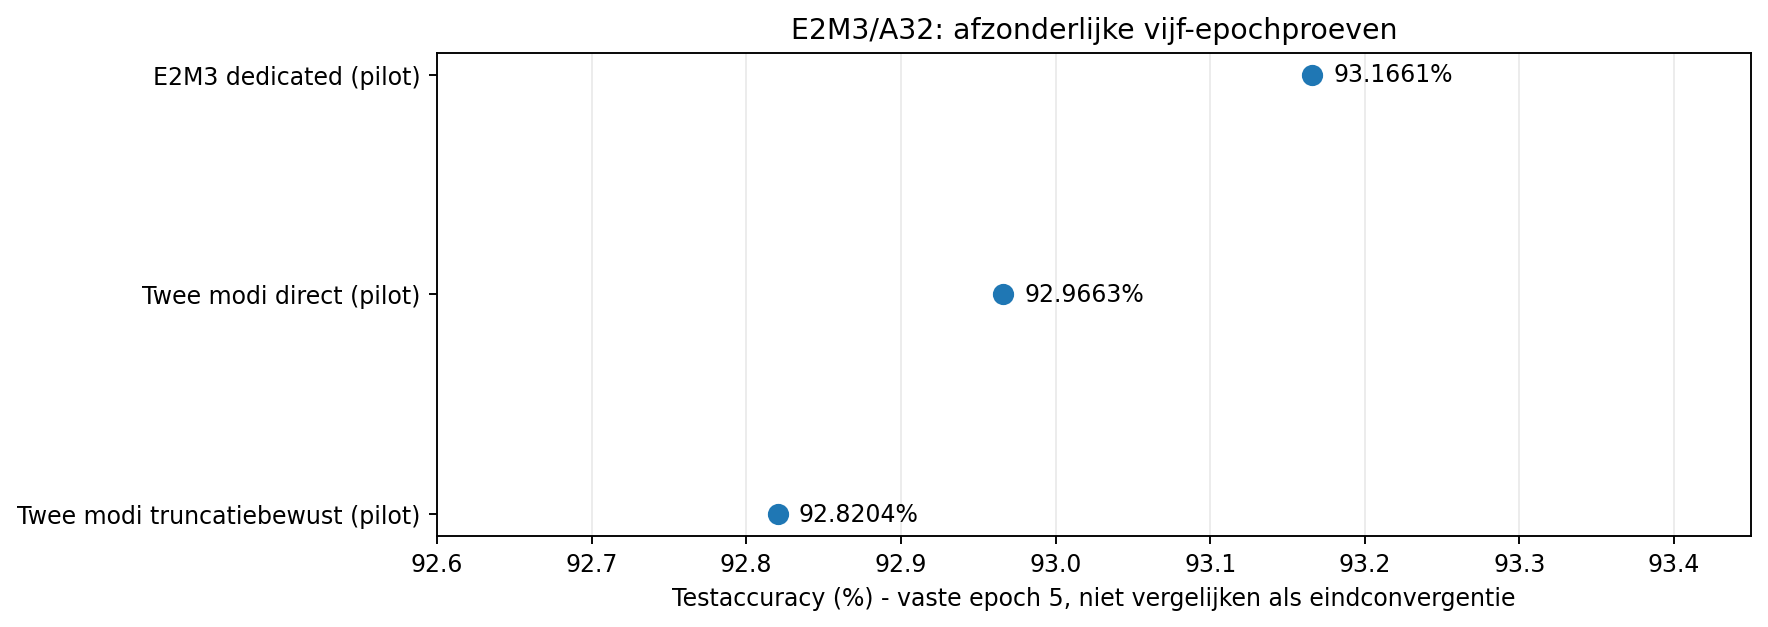

Bronnen: [single_mx_p5/epoch_metrics.csv](bronnen/single_mx_p5/epoch_metrics.csv) | [dual_p5/epoch_metrics.csv](bronnen/dual_p5/epoch_metrics.csv) | [trunc_p5/epoch_metrics.csv](bronnen/trunc_p5/epoch_metrics.csv).

In [16]:
hp=[]
for rid,label in [('single_mx_p5','E2M3 dedicated (pilot)'),('dual_p5','Twee modi direct (pilot)'),('trunc_p5','Twee modi truncatiebewust (pilot)')]:
    q=M.final_row(D,rid,6,epoch=5)
    hp.append({'run_id':rid,'traject':label,'epoch':5,'correct1':int(q.correct1),'accuracy_percent':q.accuracy_percent})
hp=pd.DataFrame(hp)
fig,ax=plt.subplots(figsize=(10.5,3.8))
y=np.arange(len(hp));ax.plot(hp.accuracy_percent,y,'o',linestyle='none',markersize=8)
ax.set_yticks(y,hp.traject);ax.invert_yaxis();ax.set_xlim(92.6,93.45)
for yi,value in zip(y,hp.accuracy_percent):ax.annotate(f'{value:.4f}%',(value,yi),xytext=(9,0),textcoords='offset points',va='center')
ax.set(title='E2M3/A32: afzonderlijke vijf-epochproeven',xlabel='Testaccuracy (%) - vaste epoch 5, niet vergelijken als eindconvergentie')
ax.grid(axis='x',alpha=0.25);savefig(fig,'09_E2M3_pilots_apart')
hp.to_csv(BASE/'afgeleid/E2M3_pilots_apart.csv',index=False)
bron(['single_mx_p5','dual_p5','trunc_p5'])


## C. Conversie zonder training en de A/B/C-diagnose
### Eerste gewichts-MX-conversie van de oorspronkelijke vijfmodusreferentie
W32/A32 uit een reeds gezamenlijk getraind model is hier de bron. Dit is geen nieuwe dedicated W32-training. MX-uitgeschakelde wrapper en herladen MX-export controleerden integratie en opslag.

In [17]:
x=D['cast'].pivot_table(index=['role','epoch'],columns='mode',values='accuracy_percent').reset_index()
tabel(x,{c:'{:.4f}' for c in x.columns if c not in ['role','epoch']})
bron(['cast'],'metrics.csv')
x=D['gap'].pivot_table(index=['role','epoch'],columns='path',values='accuracy_percent').reset_index()
tabel(x,{c:'{:.4f}' for c in x.columns if c not in ['role','epoch']})
bron(['gap'],'metrics.csv')
paired=M.read_csv(BASE/'bronnen/gap/paired_metrics.csv')
# Display recorded per-image transitions without assuming new paired predictions exist.
tabel(paired[['epoch','comparison','accuracy_difference_pp','prediction_changes','correct_to_wrong','wrong_to_correct','wrong_to_other_wrong']].rename(columns={'epoch':'Epoch','comparison':'Vergelijking','accuracy_difference_pp':'Verschil (pp)','prediction_changes':'Andere klasse','correct_to_wrong':'Correct naar fout','wrong_to_correct':'Fout naar correct','wrong_to_other_wrong':'Fout naar andere fout'}), {'Verschil (pp)':'{:.4f}'})
bron(['gap'],'paired_metrics.csv')
note('De A/B/C-paarcijfers zijn afkomstig uit de eerdere exportevaluatie. Haar grote NPZ-bestanden zijn niet nodig voor dit samenvattingsnotebook en niet meegekopieerd; CSV/JSON blijven ongewijzigd. Individuele voorspellingen van de latere truncatiebewuste training ontbreken, dus daarmee is hier geen nieuwe gepaarde statistische toets uitgevoerd.')

role,epoch,MXFP6_E2M3_A32,reference_W32_A32,stored_MXFP6_E2M3_A32,wrapper_MX_off_A32
best,54,94.9600,94.9447,94.9600,94.9447
last,100,94.7296,94.7872,94.7296,94.7872


Bronnen: [cast/metrics.csv](bronnen/cast/metrics.csv).

role,epoch,A_direct_E2M1,B_round_from_E2M3,C_truncate_E2M3,H_source_E2M3
best_E2M3_test,75,94.9255,94.6374,93.7346,95.1560
last_epoch,100,95.0254,94.4530,93.5810,95.0330


Bronnen: [gap/metrics.csv](bronnen/gap/metrics.csv).

Epoch,Vergelijking,Verschil (pp),Andere klasse,Correct naar fout,Fout naar correct,Fout naar andere fout
75,C_minus_A,-1.1908,1157,636,326,195
75,B_minus_A,-0.2881,727,327,252,148
75,C_minus_B,-0.9027,1116,580,345,191
75,A_minus_H,-0.2305,432,203,143,86
100,C_minus_A,-1.4444,1087,635,259,193
100,B_minus_A,-0.5724,706,358,209,139
100,C_minus_B,-0.8720,1096,570,343,183
100,A_minus_H,-0.0077,424,171,169,84


Bronnen: [gap/paired_metrics.csv](bronnen/gap/paired_metrics.csv).

De A/B/C-paarcijfers zijn afkomstig uit de eerdere exportevaluatie. Haar grote NPZ-bestanden zijn niet nodig voor dit samenvattingsnotebook en niet meegekopieerd; CSV/JSON blijven ongewijzigd. Individuele voorspellingen van de latere truncatiebewuste training ontbreken, dus daarmee is hier geen nieuwe gepaarde statistische toets uitgevoerd.

## D. Alle beste en laatste hoofdresultaten
Per run blijft de oorspronkelijke selectie op de hoge/actieve testaccuracy behouden. Een rij met het beste checkpoint en een andere met epoch 100 zijn **twee rapportagerollen**, geen onafhankelijke modellen. Beste lage scores van andere epochs worden niet bij de geselecteerde hoge modus gevoegd.

Training,Uitvoering,Geselecteerde epoch,Accuracy geselecteerd (%),Accuracy epoch 100 (%)
W32/A32 afzonderlijk,W32/A32,53,94.7449,94.5452
E2M3/A32 afzonderlijk,E2M3/A32,73,94.8679,94.8256
E2M1/A32 afzonderlijk,E2M1/A32,97,94.9063,94.8218
Gezamenlijk: directe MX-kwantisatie,E2M3/A32,75,95.1560,95.0330
Gezamenlijk: directe MX-kwantisatie,E2M1/A32,75,94.9255,95.0254
Gezamenlijk: truncatiebewust,E2M3/A32,52,95.0753,94.9639
Gezamenlijk: truncatiebewust,E2M1/A32,52,95.0100,94.9408


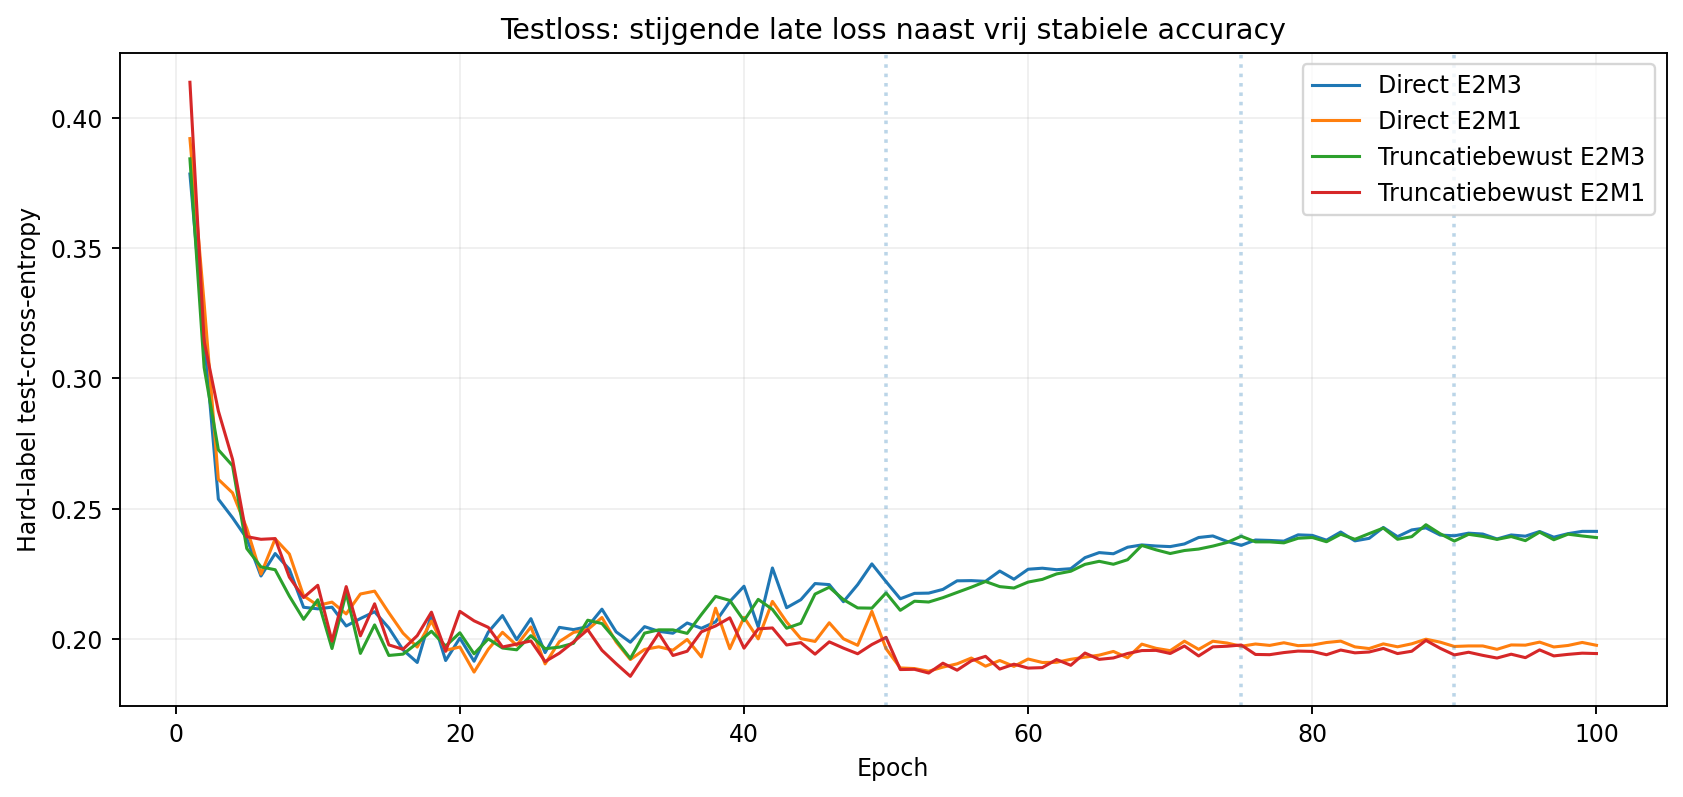

In [18]:
tabel(EIND[['methode','modus','best_epoch','best_accuracy_percent','accuracy_percent']].rename(columns={'methode':'Training','modus':'Uitvoering','best_epoch':'Geselecteerde epoch','best_accuracy_percent':'Accuracy geselecteerd (%)','accuracy_percent':'Accuracy epoch 100 (%)'}),{'Accuracy geselecteerd (%)':'{:.4f}','Accuracy epoch 100 (%)':'{:.4f}'})
fig,ax=plt.subplots(figsize=(10,4.8))
for rid,bit,label in [('dual100',6,'Direct E2M3'),('dual100',4,'Direct E2M1'),('trunc100',6,'Truncatiebewust E2M3'),('trunc100',4,'Truncatiebewust E2M1')]:
    df=D['metrics'][rid].query('phase == "test" and weight_bits == @bit')
    ax.plot(df.epoch,df.objective_loss,label=label,linewidth=1.3)
for e in [50,75,90]:ax.axvline(e,linestyle=':',alpha=.3)
ax.set(xlabel='Epoch',ylabel='Hard-label test-cross-entropy',title='Testloss: stijgende late loss naast vrij stabiele accuracy')
ax.legend();ax.grid(alpha=.2)
savefig(fig,'07_testloss_direct_en_truncatie')

## E. Opslagberekeningen per laag en FP32-trainingsstaat
Deze tabellen maken de tellers controleerbaar. Padding wordt meegerekend; biases/eerste/laatste laag en BN worden niet weggegooid. Codes zijn gepakt, niet als een uint8 per zesbitgewicht geteld.

Het bewaren van alle vijf BN-banken volgt de huidige implementatie. Een geoptimaliseerde uitrol kan ongebruikte banken verwijderen, maar dat is een andere layoutvariant, niet het gemeten huidige bestand.

In [19]:
tabel(LAGEN)
inv=M.read_json(BASE/'bronnen/tensorinventaris.json')
bnrows=[]
for active in [['32'],['32','4'],['1','2','4','8','32']]:
    aux=sum(x['bytes'] for x in inv['tensors'] if not x['mx_target'] and (x['bn_bank'] is None or x['bn_bank'] in active))
    bnrows.append({'Te bewaren BN-banken':','.join(active),'Overige staat bytes':aux,'FP32 totaal':S['fp32_target_bytes']+aux,'E2M3 bron totaal':S['high_bytes']+aux,'Status':'Huidige layout' if len(active)==5 else 'Alleen berekend, geen pruning uitgevoerd'})
tabel(pd.DataFrame(bnrows))

note('### Minimale blijvende trainingsstaat: model + twee Adam-momenten\n**Layoutberekening, geen complete geheugenmeting.** Alleen actieve parameters hebben Adam-momenten; overige BN-banken blijven wel als modelstaat aanwezig. Gradients, Adam-stapscalars, activaties, broncaches en werkruimtes zijn niet inbegrepen. Daarom mogen deze getallen niet als piek-RAM of piek-VRAM worden genoemd.')
tabel(TRAINSTAAT[['run_id','model_state_bytes_including_BN_buffers','adam_two_moments_bytes','subtotal_state_plus_moments_bytes']].rename(columns={'run_id':'Run','model_state_bytes_including_BN_buffers':'Modelstaat (B)','adam_two_moments_bytes':'Twee Adam-momenten (B)','subtotal_state_plus_moments_bytes':'Subtotaal (B)'}))
note('De mastergewichten en optimizer zijn voorlopig FP32. De compacte uitvoerbron verwijdert die kosten niet tijdens training. Een hervatcheckpoint bevat nog extra toestand en is geen eerlijke byte-referentie voor een inferentie-export.')

layer,n_weights,blocks,padded_slots,fp32_weight_bytes,high_code_bytes,low_code_bytes,scale_bytes,high_bytes,low_bytes
layers.3,1728,64,320,6912,1536,1024,64,1600,1088
layers.6,2304,80,256,9216,1920,1280,80,2000,1360
layers.10,4608,160,512,18432,3840,2560,160,4000,2720
layers.13,9216,288,0,36864,6912,4608,288,7200,4896
layers.16,9216,288,0,36864,6912,4608,288,7200,4896
layers.20,102400,3200,0,409600,76800,51200,3200,80000,54400


Te bewaren BN-banken,Overige staat bytes,FP32 totaal,E2M3 bron totaal,Status
32,10896,528784,112896,"Alleen berekend, geen pruning uitgevoerd"
"32,4",12984,530872,114984,"Alleen berekend, geen pruning uitgevoerd"
"1,2,4,8,32",19248,537136,121248,Huidige layout


### Minimale blijvende trainingsstaat: model + twee Adam-momenten
**Layoutberekening, geen complete geheugenmeting.** Alleen actieve parameters hebben Adam-momenten; overige BN-banken blijven wel als modelstaat aanwezig. Gradients, Adam-stapscalars, activaties, broncaches en werkruimtes zijn niet inbegrepen. Daarom mogen deze getallen niet als piek-RAM of piek-VRAM worden genoemd.

Run,Modelstaat (B),Twee Adam-momenten (B),Subtotaal (B)
single_fp100,537136,1055440,1592576
single_mx100,537136,1055440,1592576
dedicated_e2m1_100,537136,1055440,1592576
dual100,537136,1057488,1594624
trunc100,537136,1057488,1594624
any100,537136,1063632,1600768


De mastergewichten en optimizer zijn voorlopig FP32. De compacte uitvoerbron verwijdert die kosten niet tijdens training. Een hervatcheckpoint bevat nog extra toestand en is geen eerlijke byte-referentie voor een inferentie-export.

## F. Reproduceerbaarheid en ontbrekend bewijs
Het notebook controleert de byte-identiteit van de meegekopieerde bronnen tegen een manifest, volledigheid van de metricrijen, correcte aantallen, learning-rates, checkpointselectie en onderlinge CSV/JSON-consistentie. Het voert **niet opnieuw alle eerdere modeltests** uit en opent geen onderzoekscheckpoint.

De 200 samplevolgordehashes bij een honderd-epochpaar bestaan uit honderd train- en honderd testvolgordes. Gelijke hashes zijn een controle op de geregistreerde volgorde, niet op volledig deterministische GPU-berekeningen.

De dedicated run wordt aanvullend gecontroleerd tegen het geleverde codepakket: de 38 geregistreerde pakkethashes, het E2M1-formaat, de 100 epochs, 57.300 updates, learning rates, de eigen beste/laatste selectie en gepaarde volgorde-/omgevingseigenschappen. De exportgewichten en individuele voorspellingen ontbreken in de bundel: die zijn niet opnieuw uitgevoerd. Bestaande bronbestanden zijn ongewijzigd gekopieerd uit v1.


In [20]:
tabel(D['audits'])
tabel(D['pair_checks'].drop(columns='note').rename(columns={'run_a':'Run A','run_b':'Run B','initialization_hash_equal':'Zelfde initialisatie','order_hashes_equal':'Gelijke volgordehashes','order_hashes_compared':'Vergeleken hashes','environment_equal':'Zelfde omgeving','backend_equal':'Zelfde backend'}))
checks={'schema':'meeting-overview-checks-v2','source_files_verified':len(D['integrity']),'run_audits':D['audits'].to_dict(orient='records'),'pair_checks':D['pair_checks'].to_dict(orient='records'),'dedicated_check':NIEUW,'tensor_inventory':{'fp32_total_bytes':S['fp32_all_state_bytes'],'target_weights':S['n_weights'],'blocks':S['blocks'],'padding':S['padding']},'limitations':['reported hash consistency, not reexecution of models','no trained checkpoints or latest exports in package','one seed per method; no independence across epochs','test was used for checkpoint selection and development','storage is explicit layout arithmetic, not energy/VRAM measurement','dedicated E2M1 added; no full train+extra or continual learning results','early microexperiment raw outputs unavailable here']}
(BASE/'afgeleid/controle_resultaat.json').write_text(json.dumps(checks,indent=2,ensure_ascii=False),encoding='utf8')
for name,df in [('hoofdresultaten',EIND),('E2M1_vergelijking_epoch100',E2M1_COMPARE),('E2M3_vergelijking_epoch100',E2M3_COMPARE),('truncatiekloof_epoch100',KLOOF),('looptijden_gemeten',TIJD),('opslag_per_laag',LAGEN),('representaties',REPRESENTATIES),('flexibele_bron_scenarios',SCENARIOS),('gerapporteerde_bestandsgrootten',FYSIEK),('trainingsstaat_berekening',TRAINSTAAT),('pilot_overzicht',pilots)]:
    df.to_csv(BASE/'afgeleid'/f'{name}.csv',index=False)
(BASE/'afgeleid/opslag_tellingen.json').write_text(json.dumps(S,indent=2),encoding='utf8')
print('Controle voltooid. Alleen afgeleide tabellen en figuren geschreven; bronnen zijn niet gewijzigd.')

run_id,label,epochs,modes,optimizer_steps,metric_rows,best_epoch,warnings,status
svhn_full_p5,Any-Precision - train + extra (pilot),5,"1,2,4,8,32",23610,50,5,2,PASS (rapportcontrole)
svhn_train_p5,Any-Precision - train-only (pilot),5,"1,2,4,8,32",2865,50,5,2,PASS (rapportcontrole)
any100,"Any-Precision, vijf W/A-modi",100,"1,2,4,8,32",57300,1000,54,2,PASS (rapportcontrole)
single_mx_p5,E2M3 afzonderlijk (pilot),5,6,2865,10,5,2,PASS (rapportcontrole)
single_fp_p5,W32/A32 afzonderlijk (pilot),5,32,2865,10,5,2,PASS (rapportcontrole)
single_mx100,E2M3 afzonderlijk,100,6,57300,200,73,2,PASS (rapportcontrole)
single_fp100,W32/A32 afzonderlijk,100,32,57300,200,53,2,PASS (rapportcontrole)
dual_p5,Twee MX-modi direct (pilot),5,"4,6",2865,20,5,2,PASS (rapportcontrole)
dual100,Twee MX-modi direct,100,"4,6",57300,400,75,2,PASS (rapportcontrole)
trunc_p5,Twee MX-modi truncatiebewust (pilot),5,"4,6",2865,20,4,2,PASS (rapportcontrole)


Run A,Run B,Zelfde initialisatie,Gelijke volgordehashes,Vergeleken hashes,Zelfde omgeving,Zelfde backend
single_fp100,single_mx100,True,200,200,True,True
dual100,trunc100,True,200,200,True,True
single_mx100,dual100,True,200,200,True,True
dedicated_e2m1_100,single_mx100,True,200,200,True,True
dedicated_e2m1_100,dual100,True,200,200,True,True
dedicated_e2m1_100,trunc100,True,200,200,True,True


Controle voltooid. Alleen afgeleide tabellen en figuren geschreven; bronnen zijn niet gewijzigd.


## G. Bronnen en praktische instructies

**Eigen onderzoeksgegevens:** de links bij tabellen verwijzen naar ongewijzigde bestanden uit de aangeleverde feedbackbundels. [bronmanifest.json](bronmanifest.json) registreert iedere oorspronkelijke ZIP-naam, SHA-256, kopie en oorspronkelijke resultatenmap. Dubbel geuploade vijf-epochbundels zijn niet als nieuwe runs meegeteld.

**Code als bron:** [CNN-8](bronnen/code/models/svhn_quan.py), [oorspronkelijke quantisatoren](bronnen/code/models/quan_ops.py), [trainingslus](bronnen/code/train.py). [tensorinventaris.json](bronnen/tensorinventaris.json) legt de shape/dtype-telling vast; geen checkpointinhoud gereconstrueerd.

**Literatuurcontext uit de projectbronnen (niet als eigen resultaat geteld):**

[L1] *Microscaling Data Formats for Deep Learning*, aangeleverde `microscaling_data_formats_for_deep_learning_ResearchPaper.pdf`, p.3 tabel 1 en Algorithm 1; p.4 voor de FP32-master in de beschreven training. Het huidige experiment kwantiseert uitsluitend de zes geselecteerde gewichtsblokken, niet de volledige compute flow uit de paper.

[L2] *Any-Precision Deep Neural Networks*, aangeleverde `Any-Precision_Deep_Neural_Networks_ResearchPaper.pdf`, p.5 trainingsrecept en p.6 tabel 1. De paper gebruikt SVHN train + extra, terwijl de hoofdexperimenten hier train-only zijn. De historische paperseed en volledige herkomst van de cijfers zijn niet vastgesteld.

[L3] *TruncQuant: Truncation-Ready Quantization for DNNs with Flexible Weight Bit Precision*, aangeleverde TruncQuant-paper, p.1-2 voor de kwantisatie-truncatiekloof en de opslagmotivatie. De gepubliceerde energiewinst en opslagfactoren zijn **niet** op onze CNN overgenomen.

[L4] `Thesis Truncation+MX_Onderwerp.docx`, Description; `Truncation+MX MT Kick-off_Onderwerp.pptx`, slides over de software- en hardwaredoelen: een flexibel MX-model, continual learning en geheugen/streamer-co-design. Die bredere doelen zijn nog geen afgeronde resultaten.

**Uitvoeren:** pak het volledige pakket uit, open dit notebook in VS Code, kies `.venv-train`, en voer Run All uit. Nodig: Python, pandas, numpy, matplotlib en IPython. Geen PyTorch/GPU nodig voor dit overzicht. De HTML-versie bevat reeds uitgevoerde tabellen en figuren en is direct bruikbaar tijdens de meeting. De SVG/PNG-figuren staan in `figuren/`.

**V2-herkomst:** dedicated E2M1 is toegevoegd uit `feedback_bundle(20261021-171049).zip`. Zie [aanvullende controle](afgeleid/dedicated_controle.json) en [wijzigingen t.o.v. v1](WIJZIGINGEN_V2.md). De E2M3-figuur houdt een conversie van een eerder vijfmodusmodel apart van E2M3-bewuste training. Herhaalde evaluaties van dezelfde hoge bron worden niet als extra onafhankelijke experimenten geteld.
